# Milestone 1 - Data Crawling
- **Course:** CSC14119 - Introduction to Data Science
- **Group:** 03
- **Project:** arXiv Project
- **Date:** October 2026
- **Report Site:** [GitHub Pages Documentation](https://duynhat1705.github.io/Intro2DS-Group3-Report/)
- **Repository:** [Report Repository](https://github.com/DuyNhat1705/Intro2DS-Group3-Report) | [Shared Code Repository](https://github.com/DuyNhat1705/Intro2DS-Group3-Source)
---

# Setup

This section sets up the execution environment, imports required libraries, configures file system paths, and defines data loader functions. 

All tables and figures in this notebook are executed and rendered dynamically from the pipeline's per-paper JSONL log files and auditable system benchmark metrics.

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import milestone1_section3 as m1s3
from src import milestone1_section4 as m1s4

# 1. Overview

## 1.1 Goal and Scope
The goal of Milestone 1 is to programmatically collect the assigned range of **arXiv** papers, including every available source version, paper metadata, and reference metadata from **Semantic Scholar**. The resulting corpus provides the working input for the parsing and machine learning tasks in Milestones 2 and 3.

The scope encompasses:

1. **Assigned Entry Discovery:** Resolving the instructor-assigned IDs through the arXiv API, collecting titles, authors, submission and revision dates, and venue when available, and identifying the latest version suffix to determine the full version range. Repository-scale harvesting through OAI-PMH or Kaggle is outside the milestone's scope.
2. **Every-Version Source Collection:** Retrieving each version, including `v1` for papers without revisions, from `https://export.arxiv.org/src/<id>v<n>`. Handle the different source formats and retain an empty version record when no TeX source is available, including PDF-only or Word submissions.
3. **Selective Extraction and Figure Removal:** Keeping only `.tex` and `.bib` files while preserving their contents and relative paths. Figure binaries and other file types are excluded during extraction; LaTeX figure environments and `\includegraphics` commands remain untouched for Milestone 2.
4. **Reference Metadata and Corpus Organization:** Crawling reference metadata for each publication through the Semantic Scholar API and retaining all returned references locally, including those without arXiv IDs. Organize sources by publication and version with associated metadata, preserving original arXiv identifiers, including legacy IDs. The corpus supports the final `papers` table and the `references` table, whose published rows require an arXiv ID for the cited paper.
5. **Auditable Evaluation and Reporting:** Reporting crawl counts and success rates, average paper sizes before and after figure removal, reference counts, and reference-metadata success rates. Benchmark per-paper processing time, average processing time, total entry-discovery time, end-to-end wall time, peak and average RAM, maximum disk usage, and final output size on CPU-only Google Colab. Present the results in a public Jupyter Book with figures and tables generated during compilation.

---

## 1.2 Output Structure per Paper
Every harvested paper is stored in a clean, self-contained directory tree under the `data/` directory:

```
data/
└── <arxiv_id>/
    ├── metadata.json                 # Paper metadata (title, authors, categories, versions, abstract)
    ├── references.json               # Extracted references and Semantic Scholar metadata
    ├── v1/                           # Version 1 LaTeX source
    │   ├── main.tex
    │   ├── sections/
    │   │   ├── intro.tex
    │   │   └── methods.tex
    │   └── references.bib
    ├── v2/                           # Version 2 LaTeX source
    │   ├── main.tex
    │   └── references.bib
    └── vn/                           # Version n LaTeX source (latest version)
```

# 2. Implementation
## 2.1 Entry Discovery

The **Entry Discovery** module (`src/get_metadata.py`) serves as the foundational ingestion gateway for the entire data pipeline. Given an assigned range of raw arXiv paper identifiers, its primary objective is to resolve each ID into rich bibliographic metadata, discover all associated revisions ($v_1, v_2, \dots, v_n$), and construct the standardized `papers` schema required across all project milestones.

### 2.1.1 Two-Stage Multi-Version Resolution Workflow

Unlike standard scraping workflows that only harvest the latest preprint snapshot, this project mandates comprehensive coverage of every historical version. To achieve this while strictly minimizing redundant network calls, we design a two-stage resolution mechanism:

1. **Initial Targeted Lookup (Base Identifier Resolution):**
   - The stripped base identifier (e.g., `2310.00001` without version suffixes) is queried against the arXiv API (`export.arxiv.org/api/query`) using the official Python client `arxiv` (v4.0.1).
   - By arXiv API design, querying a base ID returns the entry corresponding to the **latest published revision**. Its canonical URI (e.g., `http://arxiv.org/abs/2310.00001v3`) carries the version suffix $vN$.
   - A regular expression parser (`re.search(r"v(\d+)$", ...)`) extracts this integer $N$, immediately uncovering the total revision count without requiring exploratory probing.

2. **Chronological Revision Timeline Reconstruction:**
   - **Single-Version Papers ($N = 1$):** The primary publication timestamp (`published`) is recorded directly as the `submission_date`, while `revised_dates` is initialized as an empty list (`[]`).
   - **Multi-Version Papers ($N > 1$):** To reconstruct the revision history efficiently, the pipeline aggregates all versioned IDs (`base_id + 'v1'`, `base_id + 'v2'`, ..., `base_id + 'vN'`) and dispatches them in a **single batched API query**. The returned entries are sorted chronologically:
     - The timestamp of version $v_1$ is designated as the initial `submission_date`.
     - The timestamps of subsequent versions ($v_2 \dots v_N$) are extracted and formatted as ISO-8601 strings (`YYYY-MM-DD`) into the `revised_dates` array.

### 2.1.2 Data Normalization & Schema Standardization

Raw responses from the API contain nested objects, unescaped whitespace, and LaTeX formatting artifacts. The module normalizes these fields into a uniform data structure:
- **Identifier Harmonization:** Normalizes input strings by stripping leading/trailing spaces and trailing revision tags (`_strip_version`).
- **Text Cleansing:** Titles and abstracts undergo whitespace collapsing (`re.sub(r"\s+", " ", ...)`), eliminating broken line-breaks from original TeX source headers.
- **Author Extraction:** Author objects are unpacked and flattened into a standardized list of strings (`[author.name for author in paper.authors]`).
- **Venue & Subject Categorization:** Formally published venues are mapped from `journal_ref` (falling back to `None` for unrefereed preprints), and all thematic tags are preserved in `categories`.

The resulting dictionary strictly adheres to the course-mandated `papers` table specification:
- `arxiv_id` *(string, non-null)*: Base arXiv identifier.
- `title` *(string)*: Cleaned title of the publication.
- `authors` *(list of strings)*: Complete list of contributing authors.
- `submission_date` *(ISO-8601 string)*: Initial submission date of version 1.
- `revised_dates` *(list of strings)*: Timestamps of subsequent revisions ($v_2 \dots v_n$).
- `venue` *(string, nullable)*: Publication journal or conference venue, if available.
- `num_versions` *(integer)*: Total number of submitted revisions.
- `categories` *(list of strings)*: Primary and secondary arXiv category tags.
- `abstract` *(string)*: Sanitized abstract text.

### 2.1.3 Polite Harvesting, Fault Tolerance & Resumability

To guarantee uninterrupted execution across thousands of papers and maintain ethical scraping standards, the module integrates three critical resilience mechanisms:

1. **Strict Rate-Limit Enforcement:**
   - In accordance with the arXiv API Terms of Use, an explicit pacing mechanism (`_respect_rate_limit`) computes the elapsed time since the previous query and guarantees a minimum delay of $\Delta t \ge 3.0$ seconds. Single-connection concurrency is enforced to avoid triggering firewall blocks.

2. **Adaptive Exponential Backoff:**
   - Network interactions are wrapped in `_fetch_arxiv_results_with_retry` with a 5-tier retry policy (`MAX_RETRIES = 5`, `BACKOFF_FACTOR = 2.0`).
   - Transient errors—including HTTP 429 (Rate Limit Exceeded), HTTP 503 (arXiv Backend Overload), HTTP 500/502/504, and socket read/connect timeouts—trigger an exponential backoff sleep ($t_{wait} = 3.0 \times 2^{attempt}$ seconds).
   - Non-retryable client errors (HTTP 400, 404) fail fast to avoid wasting rate-limit quotas.

3. **Atomic Persistence & Checkpointing:**
   - Every individual paper metadata record is serialized atomically to `<paper_dir>/metadata.json`.
   - The batch execution harness maintains an active checkpoint in `metadata_crawl_state.json`, tracking completed IDs, timestamps, and error counts.
   - When configured with `skip_existing=True`, the pipeline inspects local storage prior to issuing network requests, allowing long-running crawls to resume instantaneously after network disconnects or environment restarts.

---

## 2.2 Source Download

The source collection stage retrieves every available revision of each paper to preserve its submission history. It is implemented in `src/get_full_source.py` and coordinated by `src/scraper.ipynb`. The workflow combines revision-aware downloading, controlled request pacing, and persistent progress tracking so that large collections can be processed across multiple sessions.

### 2.2.1 Revision Discovery and Download Workflow

In the notebook, metadata discovery runs before source downloading so that each paper's `num_versions` is known. The notebook then calls `scrape_paper()` to process revisions `v1` through `vN`. When used independently, the module can also obtain the revision count from the saved `metadata.json`, falling back to the arXiv API if necessary.

Each unfinished revision is requested from `https://export.arxiv.org/src/<arxiv_id>v<n>` using a reusable HTTP session. The request uses streaming mode so that response headers can be inspected before reading the body. If the content type identifies a PDF, the body is skipped because it contains no editable LaTeX source. Otherwise, the complete response body is loaded into memory for extraction. With the default `KEEP_ARCHIVE = False`, the downloaded archive is not saved to disk after extraction.

The notebook also uses one background writer with a bounded queue, configured by `SOURCE_WRITE_QUEUE = 3`. This overlaps extraction and disk writes with the next download while limiting the number of waiting archives in memory. A completion callback reports success only after the paper's queued revisions have been stored.

### 2.2.2 Request Pacing and Error Recovery

Metadata and source requests share one `Pacer` in the notebook's arXiv lane. Source requests start at least three seconds apart, with download time counting toward this interval. After HTTP 429 or server errors, the interval increases by one second up to six seconds; after every 100 consecutive successful requests, it decreases by half a second toward the base interval.

Each download allows up to four attempts, using a numeric `Retry-After` header when available or default waits of 30, 60, and 120 seconds. Network failures also receive bounded retries. If rate limiting or server errors persist, the notebook adds cooldowns of 5, 10, and 15 minutes before stopping the lane. HTTP 403 stops the lane immediately, while HTTP 404 records the revision as unavailable.

### 2.2.3 Progress Tracking and Resumable Execution

The source state records the outcome of each revision:

| Status | Meaning |
| --- | --- |
| `done` | At least one `.tex` or `.bib` file was extracted. |
| `no_tex` | The response contains no retained source files, such as a PDF-only or empty submission. |
| `not_found` | The revision endpoint returned HTTP 404. |

These are terminal outcomes and are skipped on subsequent runs. A paper is marked complete once every expected revision has a terminal outcome; completion therefore does not imply that every revision contains LaTeX. Download or extraction failures remain unfinished and can be retried. The standalone module saves state after each stored revision using an atomic file replacement. The notebook caches state in memory and normally flushes it every 120 seconds, with a final flush during orderly shutdown. Its state is stored under `data/.state/<WORKER>/`, allowing separate range workers to keep independent checkpoints.

---

## 2.3 Extraction & Figure Removal

The extraction stage converts downloaded source packages into a compact text corpus by retaining LaTeX documents and bibliography files. Extraction and filtering take place in memory, so discarded figures do not need to be stored temporarily. The same pass measures source sizes to support comparisons of storage before and after filtering.

### 2.3.1 In-Memory Extraction and File Filtering

The `extract_tex_bib()` function in `src/get_full_source.py` identifies the response format from its contents and supports gzip-compressed tar archives, uncompressed tar archives, ZIP archives, single gzip-compressed files, and plain LaTeX files. A standalone file is saved as `main.tex` only when its content contains recognizable LaTeX commands. PDF content is also detected during extraction when it was not identified from the HTTP headers.

For supported archives, the extractor retains only files whose names end in `.tex` or `.bib`, using a case-insensitive check. Their relative directory structure is preserved under `data/<normalized_arxiv_id>/v<n>/`; for example, `sections/introduction.tex` remains in its `sections/` subdirectory. Paper directory names replace periods and slashes in the arXiv identifier with hyphens.

Figure removal is implemented through this file selection rule. Images such as PNG, JPEG, PDF, and EPS files are never written to disk, and other nonmatching files, including `.sty`, `.cls`, and `.bbl`, are excluded as well. The process does not edit LaTeX text or remove figure environments and image references from `.tex` files. Consequently, the retained corpus preserves source text for analysis but is not guaranteed to compile as a complete LaTeX project.

Archive members are checked before extraction: absolute paths and paths containing `..` components are rejected, and tar entries are processed only when they are regular files. Selected files are copied directly from the in-memory package to their destination. Under the default configuration, neither the raw archive nor discarded figures are persisted. If extraction raises an error, the incomplete revision directory is removed and the revision remains eligible for retry.

### 2.3.2 Storage Measurement and Size Reporting

During the same extraction pass, the module records the logical size of all accepted regular archive members (`full_bytes`) and the size of the retained text files (`tex_bib_bytes`). It also estimates their disk allocation by rounding each file size up to the filesystem allocation unit. These allocation estimates exclude directory and filesystem metadata.

The per-revision measurements are aggregated into three snapshots in the paper's state:

| Snapshot | Interpretation |
| --- | --- |
| `archive_only` | Size of the downloaded source package before extraction. |
| `full` | Downloaded package plus the estimated size of its fully extracted contents. |
| `tex_bib` | Retained `.tex` and `.bib` files, with the original package size recorded separately. |

The `full` snapshot describes a hypothetical storage stage: the pipeline measures archive contents without writing the complete source tree. With archives disabled, the `tex_bib` total represents retained extracted files. Paper-level size summaries count revisions with status `done`; PDF-only, empty, unavailable, and other revisions without retained text do not contribute to these summaries. This distinction allows the notebook's report to compare storage stages without treating estimated pre-filtering storage as actual disk usage.

---

## 2.4 Reference Metadata Scraping

The `get_extracting_reference.py` module enriches each arXiv paper with reference metadata from the **Semantic Scholar Academic Graph API**. It is designed to be called by the harvesting pipeline or run as a command-line batch job. Importing the module does not make network requests; API access occurs only when a fetching function or the CLI is invoked.

### 2.4.1 Identifier handling and response schema

Before lookup, the module trims the input identifier and removes a trailing arXiv version suffix (for example, `2103.00020v2` becomes `2103.00020`). Each available cited-paper record is normalized to six fields: `arxiv_id`, `ref_arxiv_id`, `ref_title`, `ref_authors`, `ref_submission_date`, and `ref_s2_id`. Missing metadata is retained as `null` (or an empty author list), so the output has a consistent shape. Records without a Semantic Scholar `paperId` are skipped.

### 2.4.2 Single-paper and batch retrieval

The single-paper path sends a `GET` request to the arXiv references endpoint, requests the fields needed for the output schema, and follows the API's `next` offset until all pages have been read. It returns `None` when the paper is not found (HTTP 404), and an empty list when the paper exists but has no retrievable references.

For higher throughput, the default CLI mode uses the Semantic Scholar batch endpoint with groups of up to 100 IDs. If a batch is rejected as too large or invalid (HTTP 400/413), it is recursively divided; a one-ID batch falls back to the single-paper endpoint. When a batch result reaches the 1,000-reference boundary, the module uses paginated single-paper retrieval to avoid silently truncating the reference list. The `--mode single` option disables batch retrieval.

### 2.4.3 Request resilience and rate limiting

All requests pass through a shared request helper. It spaces request starts by at least three seconds, uses 30-second and 60-second timeouts for GET and POST respectively, and retries transient network and server errors with increasing delays. HTTP 429 responses are retried using the server's `Retry-After` value when available, or a backoff schedule otherwise; if the retry budget is exhausted, the module raises `QuotaExhausted`. An optional `S2_API_KEY` environment variable is sent as the API key header. Other unexpected HTTP responses are surfaced as errors rather than treated as successful results.

### 2.4.4 Persistence and resumable processing

Successful non-empty results are written to `data/<arxiv_id>/references.json`. The write first goes to a temporary file and then replaces the target, reducing the chance of leaving a partially written JSON file. Processing state is appended to `data/.state/refs_done.jsonl`; each record contains the normalized ID, a status (`ok`, `no_refs`, or `not_found`), and the number of references. On a later run, IDs already present in this state file are skipped. The CLI also supports ID ranges, a global `--max-new` limit, a per-range limit, batch size, and single or batch mode.

Results of this stage, including reference counts and API success rate, are reported in Section 3.3.


---

## 2.5 Tools and Libraries Table

**Data collection**

| Library | Used in | Purpose |
|:--|:--|:--|
| `arxiv` 4.0.1 | `get_metadata.py`, `get_full_source.py`, `scraper.ipynb` | Metadata discovery and fallback revision-count lookup; the notebook shares arXiv pacing between metadata and source calls |
| `requests` 2.34.0 | `get_metadata.py`, `get_full_source.py`, `get_extracting_reference.py`, `scraper.ipynb` | HTTP access to arXiv and Semantic Scholar; reusable source session, header-based PDF skipping, bounded retries and backoff; optional Semantic Scholar API key |

**Data processing and storage**

| Library | Used in | Purpose |
|:--|:--|:--|
| `pandas` 3.1.0 | `scraper.ipynb` | Builds `papers`, `references`, `references_all` DataFrames; schema checks, deduplication, summary stats |
| `pyarrow` 26.0.0 | `scraper.ipynb` (through pandas) | Parquet backend for writing and reading the three tables; the notebook checks row counts and column names after reading them back |
| `numpy` (not explicitly pinned) | `scraper.ipynb` | Converts NumPy scalar values to native Python values for JSON exports; available through pandas dependencies |

**Monitoring and visualization**

| Library | Used in | Purpose |
|:--|:--|:--|
| `psutil` 7.2.2 | `scraper.ipynb` | System RAM information and sampled RSS of the notebook process and its children; Windows peak working-set fallback |
| `tqdm` 4.70.1 | `scraper.ipynb` | Text progress bars for parallel file loading and corpus scans during analysis |
| `matplotlib` 3.11.2 | `scraper.ipynb` | Sanity-check plots: memory curves, latency histograms, storage savings |
| `resource` (stdlib, Unix) | `scraper.ipynb` | OS-reported process peak RSS through `getrusage`; Windows uses the psutil fallback |

**Archive handling (stdlib)**

| Module | Used in | Purpose |
|:--|:--|:--|
| `tarfile` / `io` | `get_full_source.py` | Reads `.tar` and `.tar.gz` packages from in-memory byte buffers; copies only `.tex`/`.bib` regular files after relative-path checks |
| `gzip` | `get_full_source.py` | Decompresses single-file `.gz` submissions to `main.tex` (magic-byte check) |
| `zipfile` | `get_full_source.py` | Extracts `.tex`/`.bib` from ZIPs; filters out Word (`docx`) files |

**Filesystem and persistence (stdlib)**

| Module | Used in | Purpose |
|:--|:--|:--|
| `pathlib` | `utils.py`, `src/*.py` | Cross-platform paths (`data/<yymm-nnnnn>/v1/`), repo root resolution |
| `shutil` / `os` | `get_full_source.py`, `src/*.py` | Atomic writes (`.tmp` + `os.replace`), cleanup, true disk-cluster size (`GetDiskFreeSpaceW` / `statvfs`) |
| `json` | `src/*.py`, `scraper.ipynb` | Persists `metadata.json`, `references.json`, `source_state.json`, `summary_stats.json` |
| `csv` | `scraper.ipynb` | Exports report tables to `data/report_exports/` for Jupyter Book |

**Utilities and concurrency (stdlib)**

| Module | Used in | Purpose |
|:--|:--|:--|
| `concurrent.futures` / `threading` | `scraper.ipynb`, `get_full_source.py` | Parallel arXiv and Semantic Scholar lanes, monitoring threads, analysis file scans, state locks, and background source writing |
| `queue` | `get_full_source.py` | Bounded queue for the background extraction/writing thread; overlaps disk writes with downloads |
| `dataclasses` / `collections` | `get_full_source.py`, `scraper.ipynb` | Download/extraction result records, retry counters, and grouped statistics |
| `math` / `functools` / `ctypes` | `get_full_source.py` | Cluster-rounded disk-allocation estimates, cached allocation-unit lookup, and Windows filesystem queries |
| `re` | `src/*.py`, `scraper.ipynb` | ID normalization, version parsing (`v(\d+)$`), ISO-8601 validation |
| `logging` | `src/*.py`, `scraper.ipynb` | Timestamped logs to stderr and `scraper.log` (429s, retries, batch progress) |
| `time` | `src/*.py`, `scraper.ipynb` | Throttling, backoff, `perf_counter` / `monotonic` timing |

**Environment and Tooling**

| Tool | Version | Purpose |
|:--|:--|:--|
| Python | 3.12 in `src/intro2ds-env.yml` | Declared Conda runtime; the environment file notes that pandas 3.x requires Python ≥ 3.11 |
| Jupyter Notebook / `ipykernel` | Unpinned in `src/intro2ds-env.yml` | Notebook interface and Python kernel for orchestration and analysis |
| Google Colab + Drive | CPU runtime | Benchmark testbed for 25,000 papers; state persisted in `MyDrive/Intro2DS-Group3/data` |
| Conda / Mamba | `src/intro2ds-env.yml` | Environment definition with Python 3.12 and pinned pipeline packages |
| Git / GitHub | Unpinned | Repository version control; the notebook clones or updates the repository in Colab |
| Jupyter Book (report consumer) | Not declared as a pipeline dependency | The notebook exports statistics, tables, and figures to `data/report_exports/` for use in the report |

**External Services**

| Service | Endpoint | Purpose |
|:--|:--|:--|
| arXiv API / export | Atom API, `export.arxiv.org/src/{id}` | Metadata and versioned LaTeX sources (≥ 3 s delay, single connection) |
| Semantic Scholar Graph API | `/graph/v1/paper/arXiv:{id}/references`, `/paper/batch` | Citation graph: reference IDs, titles, authors, dates |


# 3. Data Statistics

This section examines the collection outcomes and composition of the arXiv dataset. It reports scraping success and failure outcomes (Section 3.1), compares source sizes before and after retaining TeX/Bib files (Section 3.2), evaluates reference retrieval and metadata completeness (Section 3.3), and describes version counts, primary categories, and submission and revision timelines (Section 3.4).

The analysis uses the collection pipeline's exported results for 25,000 target arXiv IDs across five ranges (R1–R5), each containing 5,000 IDs. Paper metadata and versioned source archives were collected from arXiv, while reference metadata was retrieved through the Semantic Scholar Academic Graph API. The reporting data, detailed metadata tables, execution logs, and processing states are stored under `statistics_data/`.

Paper-level statistics are calculated by combining the five `report_exports/R1–R5/per_paper.csv` files, preserving arXiv IDs as strings and checking their uniqueness. Per-range summaries are used for cross-checking, while category counts and range definitions describe the selected sample. Detailed Parquet tables in `tables/` support reference metadata and timeline analyses; records in `run_logs/` and `.state/` provide evidence for interpreting incomplete outcomes. Each analysis identifies its relevant population, distinguishing final paper outcomes from version-level results and repeated execution events.

## 3.1 Scraping Success Rate & Failure Breakdown

To assess the completion of data collection, this analysis uses the final exported outcomes for 25,000 target arXiv IDs, divided into five ranges (R1–R5) of 5,000 IDs each. Records are combined from the corresponding `per_paper.csv` files, with one row per unique ID. State files and execution logs are used to reconcile version-level outcomes and investigate the incomplete case.

A paper is classified as successfully collected when both metadata retrieval and source processing have the status `done`. The success rate is defined as:

$$
\text{Success Rate}
=
\frac{N_{\text{metadata = done}\,\land\,\text{source = done}}}
{N_{\text{target IDs}}}
\times 100\%.
$$

Under this definition, reference retrieval is evaluated independently in Section 3.3 and does not contribute to the `paper_success` indicator.

*Table 3.1. Data collection outcomes by ID range.*

| Range | Target IDs | Metadata completed | Source processing completed | Successful papers | Success rate |
|---|---:|---:|---:|---:|---:|
| R1 | 5,000 | 5,000 | 5,000 | 5,000 | 100% |
| R2 | 5,000 | 5,000 | 5,000 | 5,000 | 100% |
| R3 | 5,000 | 5,000 | 5,000 | 5,000 | 100% |
| R4 | 5,000 | 5,000 | 4,999 | 4,999 | 99.98% |
| R5 | 5,000 | 5,000 | 5,000 | 5,000 | 100% |
| **Total** | **25,000** | **25,000** | **24,999** | **24,999** | **99.996%** |

As shown in Table 3.1, metadata retrieval was completed for all 25,000 target IDs. Source processing was completed for 24,999 papers, yielding an overall success rate of 99.996%. One paper in R4 did not satisfy the success criterion at the time of export. Because metadata was retrieved for every target ID, the success rate among metadata-found papers is identical to the rate over all target IDs.

Paper-level completion must be distinguished from the availability of source files for individual versions. Within the collection workflow, a version may reach one of three terminal outcomes: `done`, `no_tex`, or `not_found`. The status `done` indicates that at least one `.tex` or `.bib` file was retained; `no_tex` indicates that no TeX/Bib content was retained after processing; and `not_found` indicates that the version was unavailable at the queried endpoint. Since all three are terminal outcomes, a paper with completed source processing may still include versions without retained TeX/Bib content.

*Table 3.2. Version-level processing outcomes.*

| Processing outcome | Number of versions |
|---|---:|
| TeX/Bib content retained (`done`) | 30,050 |
| No TeX/Bib content retained (`no_tex`) | 1,598 |
| Version not found (`not_found`) | 114 |
| No terminal outcome recorded | 1 |
| **Total versions reported in metadata** | **31,763** |

The 99.996% completion rate therefore describes workflow completion under the stated definition. It does not imply that LaTeX source was obtained for every version of every paper.

The incomplete paper, `2608.08374`, has three versions. Its state record shows that the first two versions were processed successfully, while the third remained incomplete. Execution logs record repeated `IncompleteRead` errors during attempts to download the third version, indicating that the response body was not fully received. Consequently, the paper was marked `source='failed'` despite the partial collection of its source files. This case illustrates the distinction between obtaining partial data and completing all expected versions.

In addition to the final outcomes, the event logs contain 15 `batch_failed` events, 47 `cooldown` events, eight `lane_stop` events, and two `time_limit` events. These counts describe execution events and cannot be interpreted directly as numbers of failed papers. A paper may encounter multiple errors before completion, while a batch-level event may affect several papers. Similarly, `cooldown` and `time_limit` events reflect execution controls or session limits and do not necessarily indicate data loss.

The results indicate a high completion rate for the selected target IDs. Reporting paper-level outcomes alongside version-level availability and execution events provides a more precise account of the collected data and the remaining gaps in source coverage.

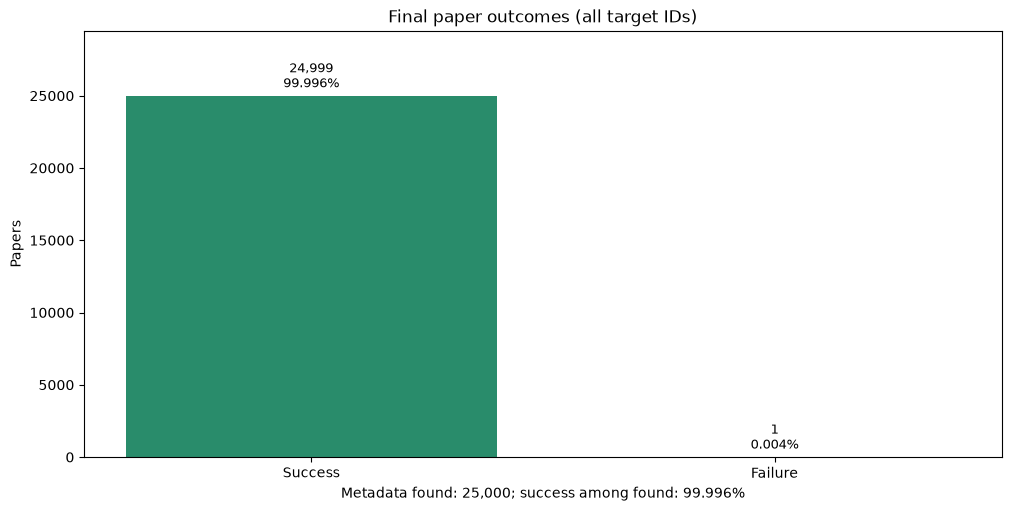

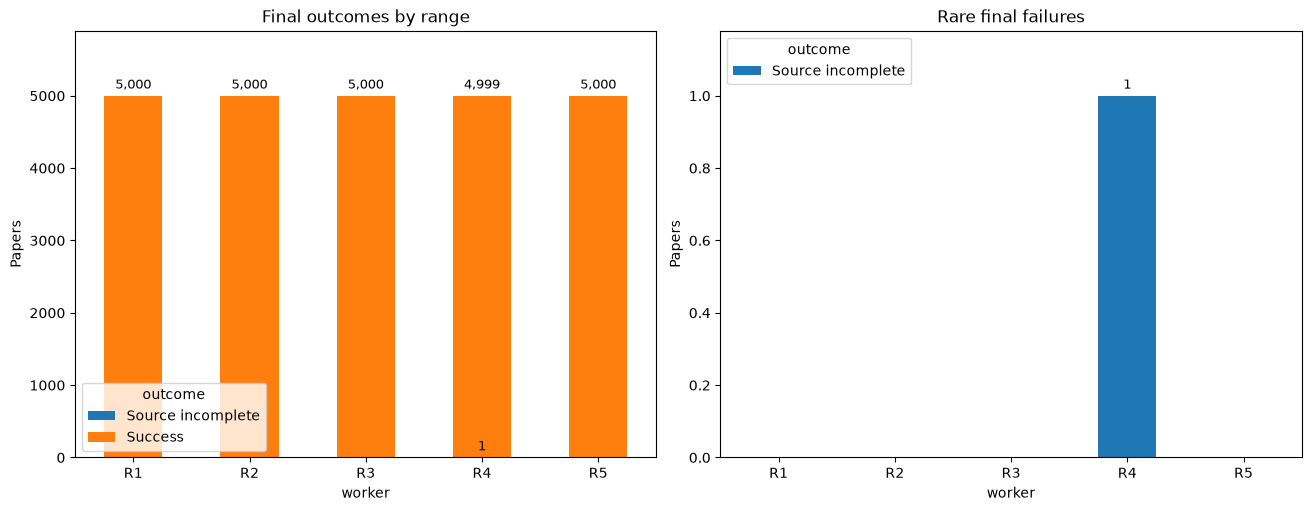

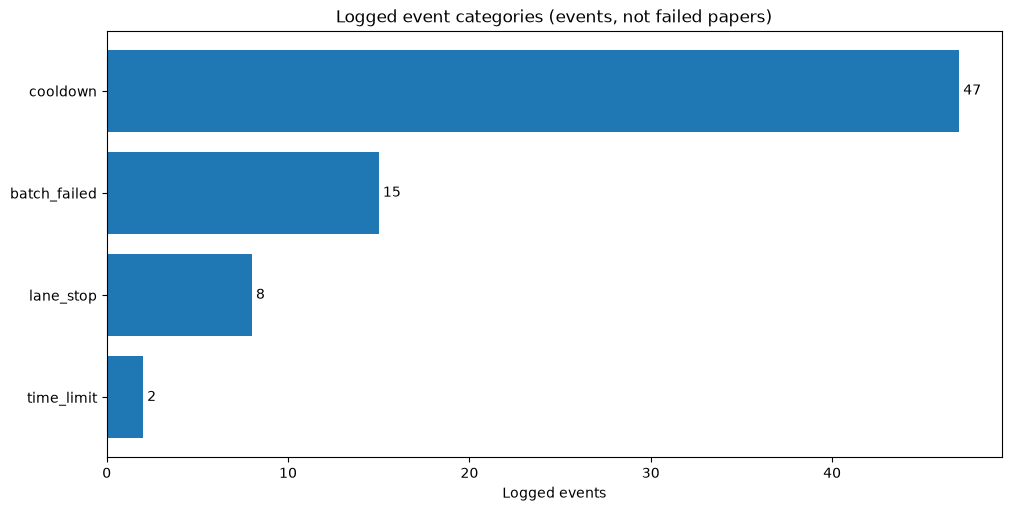

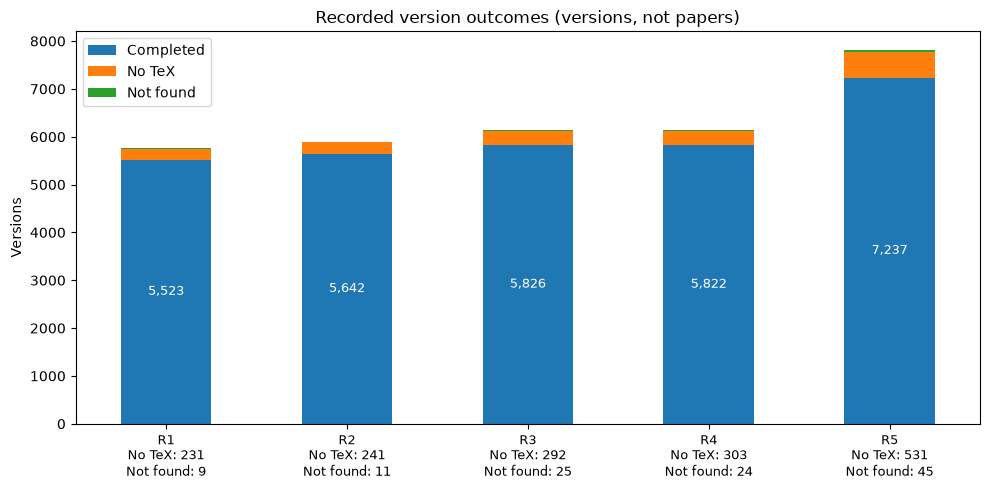

In [2]:
success_fail = m1s3.success_fail_31()
outcome_by_range = m1s3.outcome_by_range_31()
retry_errors = m1s3.retry_errors_31()
version_outcome = m1s3.version_outcome_31()

## 3.2 Paper Size Analysis: Before vs. After Figure Removal

### 3.2.1 Measurement Scope and Definitions

This analysis compares extracted source content with the TeX/Bib content retained after file filtering. The columns `size_full_bytes` and `size_tex_bib_bytes` represent file-content bytes, rather than compressed archive sizes or filesystem allocation. Paper-level values aggregate the recorded sizes of versions with retained source; they should not be interpreted as the size of a single latest-version document.

The paired comparison includes **23,659 papers (94.64% of the target IDs)** with finite measurements, a positive extracted size, and a nonnegative retained size. The remaining 1,341 records comprise 1,340 with zero extracted bytes and one with missing size measurements. The latter is the incomplete paper identified in Section 3.1. No valid pair has a negative reduction. Excluded records are not assigned an artificial reduction of zero.

For paper $i$, let $B_i$ and $A_i$ denote extracted and retained bytes. The per-paper reduction and the aggregate reduction are defined separately:

$$
R_i = 100\left(1-\frac{A_i}{B_i}\right),\qquad
R_{\mathrm{aggregate}} = 100\left(1-\frac{\sum_i A_i}{\sum_i B_i}\right).
$$

The aggregate measure weights papers by their extracted size, whereas the arithmetic mean of $R_i$ assigns equal weight to each paper. All size statistics below use the same valid paired population. Units are binary: $1\,\mathrm{MiB}=2^{20}$ bytes and $1\,\mathrm{GiB}=2^{30}$ bytes.

### 3.2.2 Overall Reduction and Size Distribution

*Table 3.3. Extracted and retained source sizes for 23,659 valid paper-level pairs.*

| Statistic | Extracted content | Retained TeX/Bib |
| --- | ---: | ---: |
| Total (GiB) | 109.12 | 4.84 |
| Mean per paper (MiB) | 4.7229 | 0.2095 |
| Median per paper (MiB) | 1.2282 | 0.1073 |
| 95th percentile (MiB) | 21.3048 | 0.4783 |
| Maximum (MiB) | 806.8881 | 76.4948 |

Total recorded content decreases from **109.12 GiB to 4.84 GiB**, a difference of **104.28 GiB** and an aggregate reduction of **95.56%**. The median per-paper reduction is **90.01%**, while the mean per-paper reduction is **69.80%**. These values describe different aspects of the distribution: larger source packages contribute more heavily to the aggregate percentage, while the lower unweighted mean shows that substantial savings are not uniform across papers.

Both size distributions are right-skewed. Before filtering, the mean is approximately 3.85 times the median, and the 95th percentile is approximately 17.35 times the median. Retained sizes remain heterogeneous: the median is 0.1073 MiB, but the maximum reaches 76.49 MiB. Consequently, neither the mean nor the total alone adequately represents a typical paper. The log-scale boxplots summarize the central distributions, and the paired scatterplot shows how individual measurements relate to the equal-size line. Outliers hidden in the boxplots remain included in the numerical summaries and scatterplot.

### 3.2.3 Heterogeneity of Savings and Storage Concentration

Among valid pairs, **17,729 papers (74.94%)** have reductions of at least 50%; **11,834 (50.02%)** reach at least 90%; and **8,617 (36.42%)** reach at least 95%. Conversely, 4,243 papers (17.93%) have reductions below 10%. Thus, a large reduction in total bytes coexists with a substantial subset whose retained source is already close in size to its extracted content. The reduction histogram and empirical cumulative distribution function (ECDF) make these two features visible without treating the aggregate percentage as a typical individual outcome.

Storage is concentrated in a relatively small subset. Ranking valid pairs by extracted size, the largest 1%, 5%, and 10% account for **16.49%, 42.63%, and 59.33%** of extracted bytes, respectively. Ranking independently by retained size, the corresponding shares are **28.72%, 41.77%, and 50.89%**. These are separate rankings and need not contain the same papers. Filtering reduces the overall byte total, but a small group of large retained records still contributes disproportionately to the remaining content.

The largest extracted record, `2511.08890`, illustrates the range of individual outcomes: its extracted content is 806.89 MiB, whereas retained TeX/Bib content is approximately 0.0377 MiB. This example establishes the presence of an extreme reduction; it does not identify the file types responsible for the removed bytes.

### 3.2.4 Differences across ID Ranges

*Table 3.4. Paired size measurements and aggregate reduction by range.*

| Range | Valid pairs | Extracted (GiB) | Retained (GiB) | Aggregate reduction |
| --- | ---: | ---: | ---: | ---: |
| R1 | 4,794 | 17.852 | 0.835 | 95.32% |
| R2 | 4,778 | 18.850 | 0.780 | 95.86% |
| R3 | 4,745 | 20.202 | 0.884 | 95.63% |
| R4 | 4,726 | 20.724 | 0.809 | 96.09% |
| R5 | 4,616 | 31.492 | 1.532 | 95.13% |

Aggregate reductions are consistently high across ranges, spanning **95.13%–96.09%**, while the underlying size distributions differ. R5 has the fewest valid pairs but the largest extracted and retained totals. It contributes **28.86% of extracted bytes and 31.65% of retained bytes**, compared with 20% of target IDs. Its median extracted size is 2.0043 MiB, compared with 0.9339–1.2149 MiB in R1–R4. Its median per-paper reduction is also the highest, at 92.97%, despite having the lowest aggregate reduction. This difference further demonstrates that per-paper medians and aggregate byte ratios are not interchangeable.

These measurements quantify **source-filtering reduction**. The retained set contains only `.tex` and `.bib` files; removed content can include figures and other file types. The size difference therefore cannot be attributed entirely to figures, and the measurements do not establish whether every dependency required to compile a complete LaTeX project was preserved.

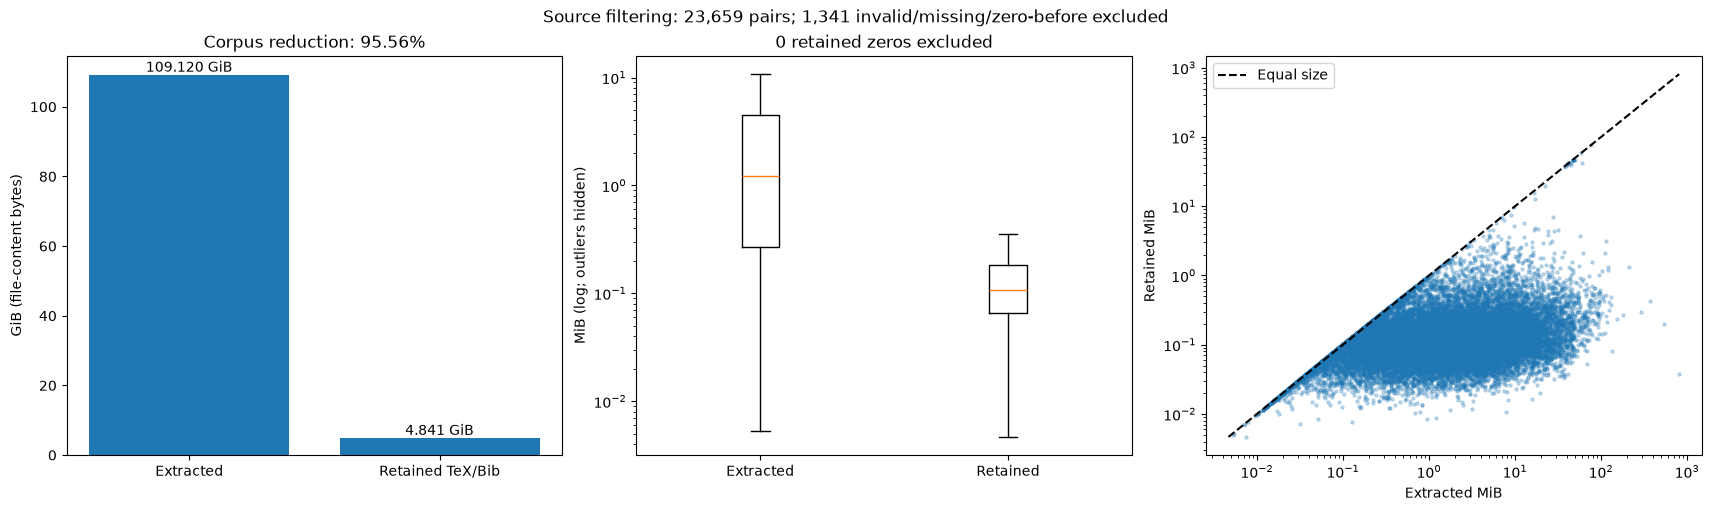

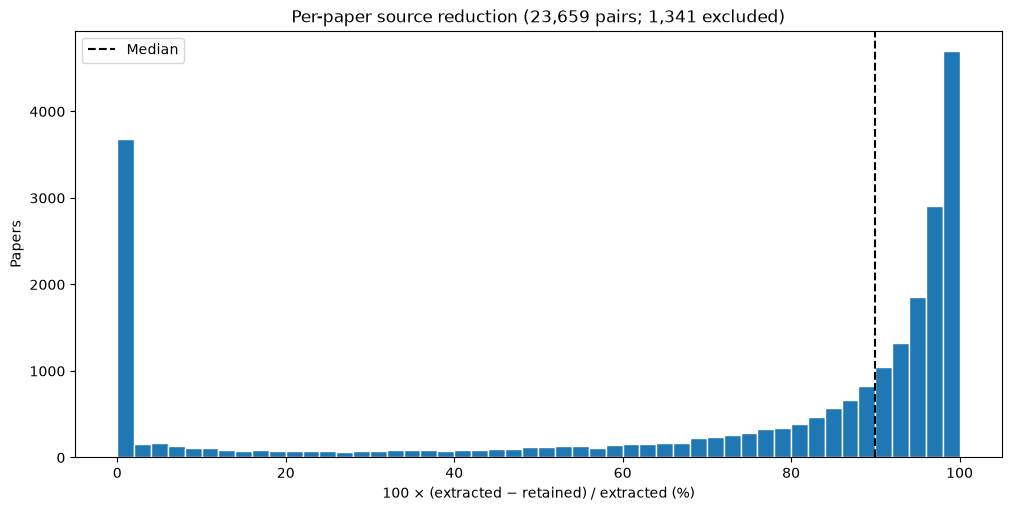

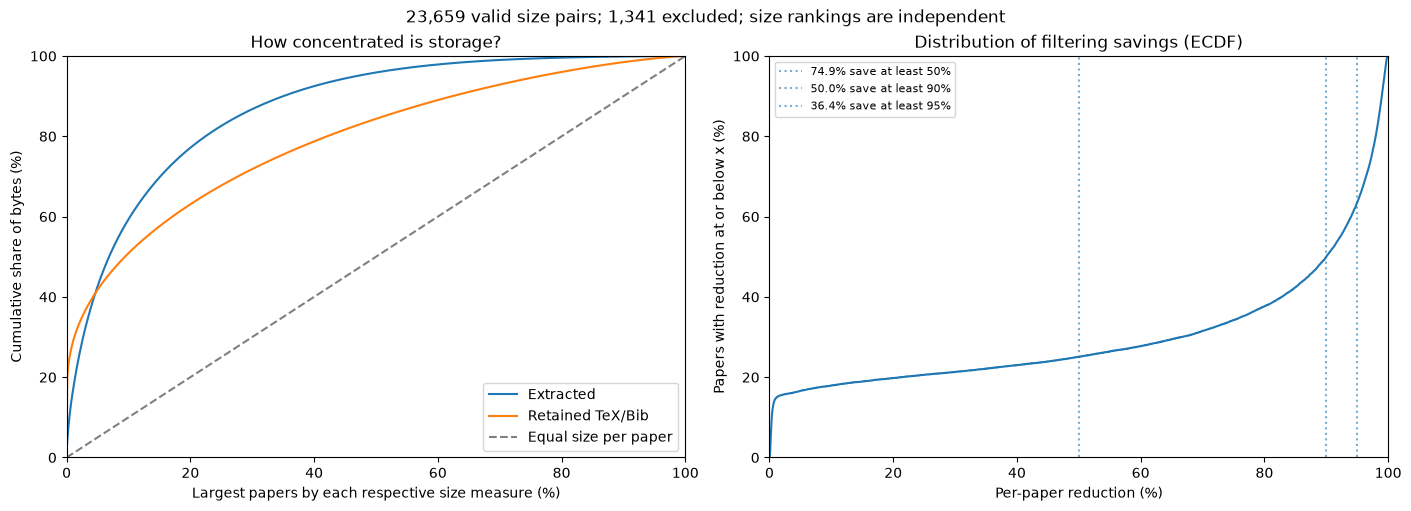

In [3]:
extracted_retained_size = m1s3.extracted_retained_size_32()
paper_reduction_32 = m1s3.paper_reduction_32()
size_concentration = m1s3.size_concentration_32()

## 3.3 Reference Statistics & Metadata Success Rate

### 3.3.1 Lookup Outcomes and Analytical Populations

Reference retrieval is evaluated for all **25,000 target papers**, independently of metadata and source-processing completion. A nonempty result has status `ok`; `no_refs` records an empty retrieved reference list; and `not_found` records an unresolved paper lookup. An empty result does not, by itself, establish that the original paper contains no bibliography. These outcomes measure the available retrieval results rather than the true number of references in every source document.

*Table 3.5. Final reference lookup outcomes over 25,000 target papers.*

| Final outcome | Target papers | Share of targets |
| --- | ---: | ---: |
| Nonempty result (`ok`) | 21,835 | 87.34% |
| Empty result (`no_refs`) | 3,155 | 12.62% |
| Paper not found (`not_found`) | 10 | 0.04% |

Using the export's definition, the nonempty retrieval rate is **87.34%**. The 3,155 empty results are reported separately from the ten `not_found` outcomes. Combining them into a single failure category would obscure the difference between an empty returned list and a paper that could not be resolved.

### 3.3.2 Reference Counts and Distribution

The 21,835 nonempty lookups contain **697,512 returned reference rows**. Direct counts from `references_all.parquet` agree with the per-paper exports, both overall and for each citing ID. These rows are citing-paper/reference observations; a cited work referenced by multiple papers can appear repeatedly. The total is therefore not the number of distinct cited publications.

Within the nonempty population, the mean is **31.94 references per paper**, the median is **27**, and the interquartile range is **17–41**. The 95th percentile is **72**, and the maximum is **512**. The mean exceeding the median and the large upper tail show that a subset of reference-rich papers contributes disproportionately to the returned records. The histogram uses a logarithmic frequency axis to retain visibility of this tail, while the range-level boxplots summarize the central distributions without plotting individual outliers.

Across all target IDs, the realized yield is **27.90 returned reference rows per target**, calculated as 697,512 / 25,000. This describes the amount actually returned for the selected targets; it does not treat empty or unresolved lookups as proof that their underlying bibliographies contain zero references.

### 3.3.3 Contrasting Coverage and Conditional Reference Counts

*Table 3.6. Reference retrieval profiles by range. Each range contains 5,000 target IDs; arXiv-linked shares use returned reference rows as the denominator.*

| Range | Nonempty lookup rate | Mean references, `ok` only | Returned references / target | arXiv-linked share |
| --- | ---: | ---: | ---: | ---: |
| R1 | 90.10% | 30.47 | 27.46 | 57.81% |
| R2 | 91.10% | 30.55 | 27.83 | 55.24% |
| R3 | 90.64% | 31.02 | 28.11 | 54.51% |
| R4 | 91.42% | 32.03 | 29.28 | 55.87% |
| R5 | 73.44% | 36.52 | 26.82 | 55.23% |

R1–R4 have nonempty lookup rates of 90.10%–91.42%; their pooled rate is **90.82%**. R5 is lower at **73.44%**, a gap of **17.38 percentage points** relative to the pooled R1–R4 rate. R5 contains 1,323 empty results, or **26.46% of its targets**, and accounts for **41.93% of all empty results** despite representing only one fifth of target IDs.

At the same time, R5 has the highest mean among nonempty lookups: **36.52 references**, compared with 30.47–32.03 in the other ranges. Its median is 32 and its 95th percentile is 82, also above the overall median of 27 and 95th percentile of 72. However, R5's realized yield is only **26.82 references per target**, the lowest of the five ranges. A comparison restricted to successful lookups would therefore conceal the substantial difference in retrieval coverage. The reference-profile figure presents nonempty rates, conditional means, and realized yields separately to make this distinction explicit.

The exports establish this contrast but do not identify its cause. Range composition and reference availability are not controlled experimentally, so the differences are descriptive rather than evidence of a causal effect of submission period or subject area.

### 3.3.4 arXiv Link Coverage and Metadata Completeness

Of all returned reference rows, **388,704 (55.73%)** contain an arXiv ID. The remaining **308,808 (44.27%)** lack this identifier, but may still contain useful bibliographic metadata. This coverage measure has a different denominator from the paper-level lookup rate. Across ranges it varies from 54.51% to 57.81%, a narrower spread than the nonempty lookup rates; R5's lower paper-level coverage is not accompanied by a comparable decrease in the arXiv-linked fraction among references that were returned.

*Table 3.7. Field presence in 697,512 returned reference rows. A field is counted as present when its value is nonempty; an author list must contain at least one nonempty entry.*

| Reference field | Nonempty rows | Completeness | Missing or empty rows |
| --- | ---: | ---: | ---: |
| `ref_title` | 697,512 | 100.00% | 0 |
| `ref_authors` | 694,519 | 99.57% | 2,993 |
| `ref_submission_date` | 635,850 | 91.16% | 61,662 |
| `ref_arxiv_id` | 388,704 | 55.73% | 308,808 |
| `ref_s2_id` | 697,512 | 100.00% | 0 |

Titles and Semantic Scholar identifiers are present in every returned row. Author information is present in **99.57%**, with 2,993 rows missing a nonempty author entry. The date field is present in **91.16%**, leaving 61,662 rows without a nonempty date. These field-presence rates describe completeness of the returned records, not independent verification of their correctness. In particular, the date check does not validate precision or chronological accuracy.

The arXiv-restricted `references.parquet` tables contain **388,704 deduplicated citing/cited arXiv links** in this export. Their scope differs from `references_all.parquet`: analyses based only on these links omit references without an arXiv identifier. High title and Semantic Scholar ID completeness among returned rows also cannot be extrapolated to the 3,165 target papers without a nonempty reference result.

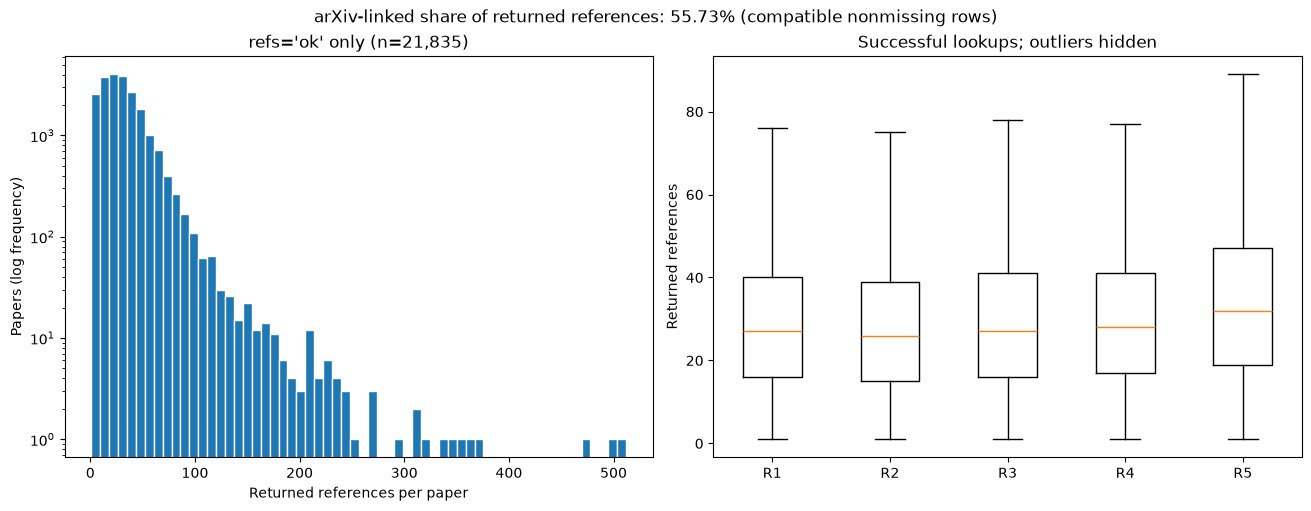

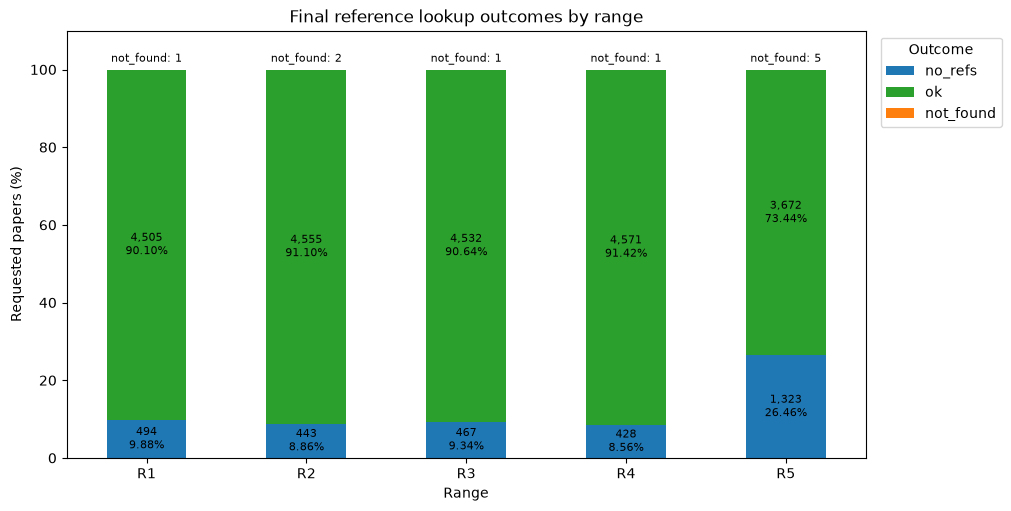

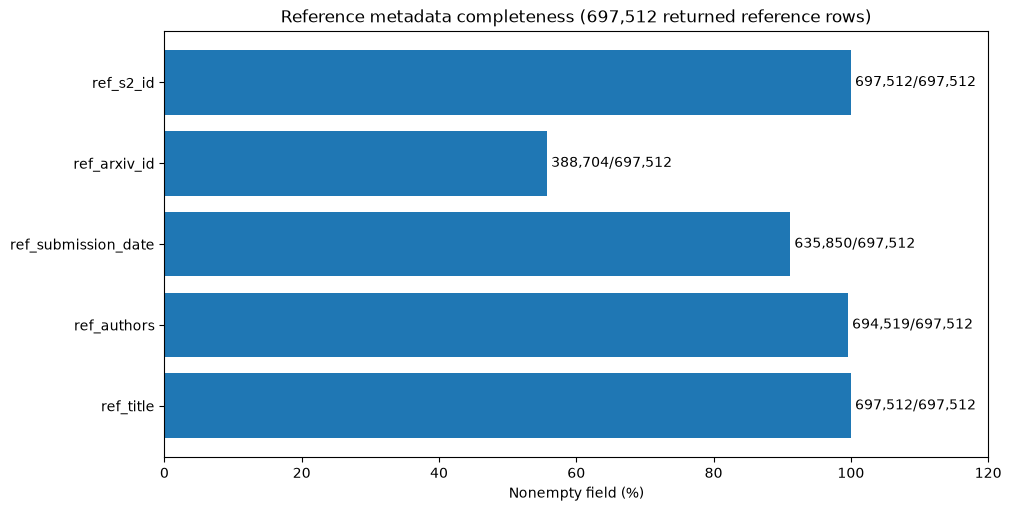

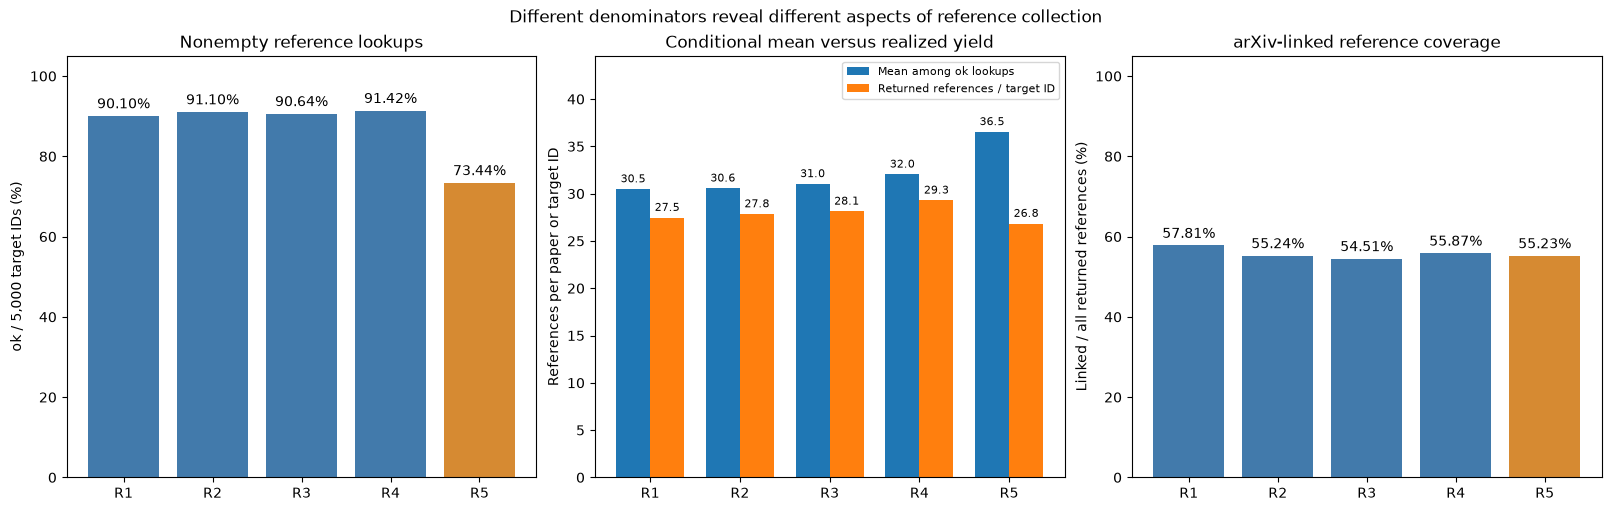

In [4]:
reference_count = m1s3.reference_count_33()
lookup_outcome = m1s3.lookup_outcome_33()
metadata_completeness = m1s3.metadata_completeness_33()
reference_profiles = m1s3.reference_profiles_33()

## 3.4 Additional Breakdowns: Versions, Categories & Timeline

### 3.4.1 Version Multiplicity

Metadata identifies **31,763 versions across 25,000 papers**, corresponding to a mean of **1.2705 versions per paper**, a median of **one**, and a 95th percentile of **two**. The largest observed version count is seven.

*Table 3.8. Distribution of version counts among all metadata-found papers.*

| Versions per paper | Papers | Share of target papers |
| --- | ---: | ---: |
| 1 | 19,701 | 78.80% |
| 2 | 4,215 | 16.86% |
| 3 | 815 | 3.26% |
| 4 | 190 | 0.76% |
| 5 | 56 | 0.22% |
| 6 | 14 | 0.06% |
| 7 | 9 | 0.04% |

Single-version papers account for **78.80%** of the sample. The **5,299 multi-version papers (21.20%)** account for **12,062 expected versions (37.98% of all versions)**. Papers with four or more versions are uncommon: 269 records, or 1.08% of targets. The expected version total exceeds the paper count by 6,763, showing the additional revision content represented in the dataset. This is a count of metadata-reported versions, not a count of HTTP requests or successfully retained source versions.

Version multiplicity also provides a useful breakdown of source-size composition. Among the 23,659 valid size pairs, multi-version papers account for **21.56% of records**, **38.95% of extracted bytes**, and **36.77% of retained bytes**. Their median retained size is **0.2164 MiB**, compared with **0.0912 MiB** for single-version papers. These are paper-level aggregates over measured versions; the comparison does not establish that individual revisions are larger. The version/storage composition figure distinguishes the paper, version, and valid-size populations explicitly.

*Table 3.9. Version and revision profiles by range. Multi-version shares use all 5,000 target papers in each range; revision-interval medians use only papers with a recorded valid revision interval.*

| Range | Expected versions | Multi-version papers | Multi-version share | Median revision interval (days) |
| --- | ---: | ---: | ---: | ---: |
| R1 | 5,763 | 671 | 13.42% | 12.0 |
| R2 | 5,894 | 770 | 15.40% | 13.0 |
| R3 | 6,143 | 950 | 19.00% | 21.5 |
| R4 | 6,150 | 941 | 18.82% | 26.0 |
| R5 | 7,813 | 1,967 | 39.34% | 126.0 |

R5 has the highest multi-version share, **39.34%**, compared with 13.42%–19.00% for R1–R4. It contributes **24.60% of all expected versions** while containing 20% of target papers. This concentration describes the composition of the collected sample; differences in observation windows must also be considered when comparing revision histories.

### 3.4.2 Primary Scientific Categories

The category exports contain **149 primary categories**, with counts summing to 25,000. Each paper contributes once, using the first category listed in its metadata. Cross-listed secondary categories are therefore not included in these counts.

*Table 3.10. Ten most frequent primary categories.*

| Primary category | Papers | Share of targets |
| --- | ---: | ---: |
| `cs.LG` | 2,091 | 8.36% |
| `cs.CV` | 2,065 | 8.26% |
| `cs.AI` | 1,562 | 6.25% |
| `cs.CL` | 1,300 | 5.20% |
| `quant-ph` | 1,040 | 4.16% |
| `cs.RO` | 1,022 | 4.09% |
| `math.CO` | 613 | 2.45% |
| `cs.CR` | 545 | 2.18% |
| `math.AP` | 541 | 2.16% |
| `cond-mat.mtrl-sci` | 446 | 1.78% |

The four most frequent categories—`cs.LG`, `cs.CV`, `cs.AI`, and `cs.CL`—together account for **28.07%** of targets. Grouping categories by their prefix, `cs` contributes **11,591 papers (46.36%)**, while `math` contributes **4,733 (18.93%)**. Together these prefixes represent **65.30%** of the sample. This prefix grouping describes the recorded labels and does not reclassify papers using their secondary categories.

Despite these concentrations, the top 15 primary categories account for only **52.37%** of papers; the remaining 134 categories contribute **47.63%**. The category bar chart therefore retains an explicit “Other” group, rather than displaying the leading categories as if they covered the entire sample.

The heatmap expresses each category as a percentage of all 5,000 papers in the corresponding range. It reveals differences that overall totals conceal. For example, `cs.AI` represents 7.66% of R4 but 4.38% of R5, whereas `cs.LG` represents 10.20% of R5 and 7.22% of R4. Such contrasts describe the selected ID windows and should not be generalized to the relative prevalence of these fields across all arXiv submissions.

### 3.4.3 Selected ID Windows and Recorded Submission Dates

*Table 3.11. Sampling windows defined in the range exports.*

| Range | Selected arXiv ID window | Target IDs |
| --- | ---: | ---: |
| R1 | `2609.27834`–`2609.32833` | 5,000 |
| R2 | `2609.17834`–`2609.22833` | 5,000 |
| R3 | `2608.14007`–`2608.19006` | 5,000 |
| R4 | `2608.04007`–`2608.09006` | 5,000 |
| R5 | `2511.06709`–`2511.11708` | 5,000 |

The selected ID prefixes correspond to November 2025, August 2026, and September 2026. These fixed windows define the collection scope and do not form a random sample of arXiv. The timeline figure instead groups each unique paper by its parsed `submission_date` from `papers.parquet`.

*Table 3.12. Distribution of recorded initial-submission months.*

| Recorded initial-submission month | Papers | Share of targets |
| --- | ---: | ---: |
| 2025-09 | 7 | 0.03% |
| 2025-10 | 59 | 0.24% |
| 2025-11 | 4,934 | 19.74% |
| 2026-04 | 11 | 0.04% |
| 2026-05 | 46 | 0.18% |
| 2026-06 | 126 | 0.50% |
| 2026-07 | 471 | 1.88% |
| 2026-08 | 10,203 | 40.81% |
| 2026-09 | 9,143 | 36.57% |

All 25,000 stored submission dates can be parsed. The three months represented by the selected ID prefixes contain **97.12% of recorded initial-submission dates**; the remaining 720 papers (2.88%) fall in other observed months. At the individual-record level, **1,279 papers (5.12%) have a recorded submission month earlier than their ID-prefix month**, and none has a later recorded month. For example, some September-prefix records have August submission dates, so the metadata-based August total exceeds the 10,000 targets selected from August-prefix ranges.

These differences show that ID-prefix months and stored initial-submission months are not interchangeable in these exports. The descriptive timeline follows the stored dates, while the sampling definition follows `ranges.csv`. Parseability alone does not validate the dates' provenance or semantics. Neither the unobserved months nor differences between observed months can be interpreted as evidence of zero activity or repository-wide submission trends.

### 3.4.4 Intervals to the Latest Observed Revision

Revision intervals are calculated from the stored initial-submission date to the latest valid date in `revised_dates`. There are **5,299 valid nonnegative intervals**, matching the number of multi-version papers. The other 19,701 papers have no recorded revision date and are excluded rather than assigned zero days. No negative interval is observed.

Among revised papers, the median interval is **29 days**, the mean is **65.62 days**, and the interquartile range is **8–81 days**. The 95th percentile is **268 days**, and the maximum is **353 days**. A total of **2,722 revised papers (51.37%)** have intervals of at most 30 days, while **4,083 (77.05%)** have intervals of at most 90 days. The mean exceeding the median reflects a substantial upper tail.

The by-range boxplot adds context to the pooled histogram. Median intervals are 12 days in R1, 13 in R2, 21.5 in R3, 26 in R4, and 126 in R5. R5 has an earlier selected ID window and a longer opportunity for revisions to be observed before the collection snapshot. The range differences therefore cannot be interpreted as intrinsic differences in revision speed. Moreover, these are intervals to the **latest observed revision**, not waiting times to the first revision or evidence that a paper will never be revised again.

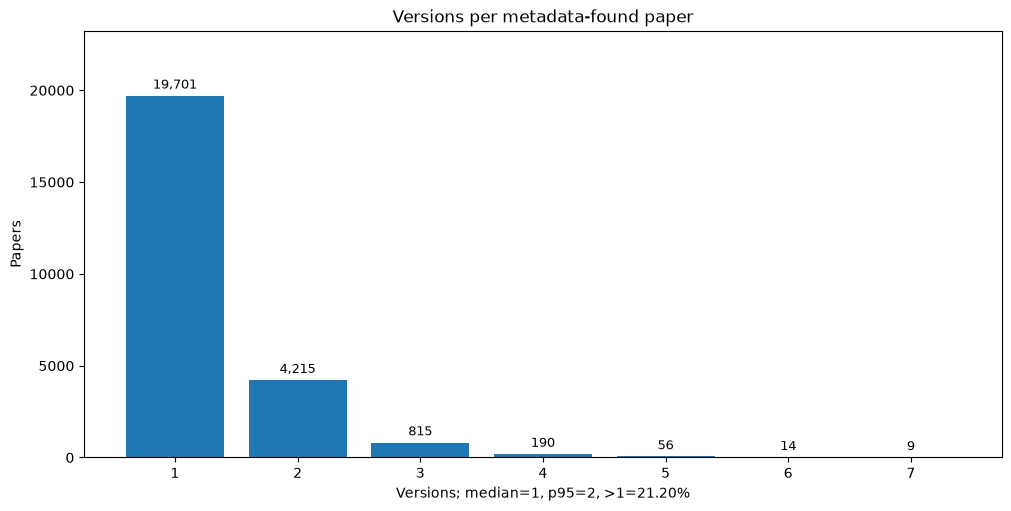

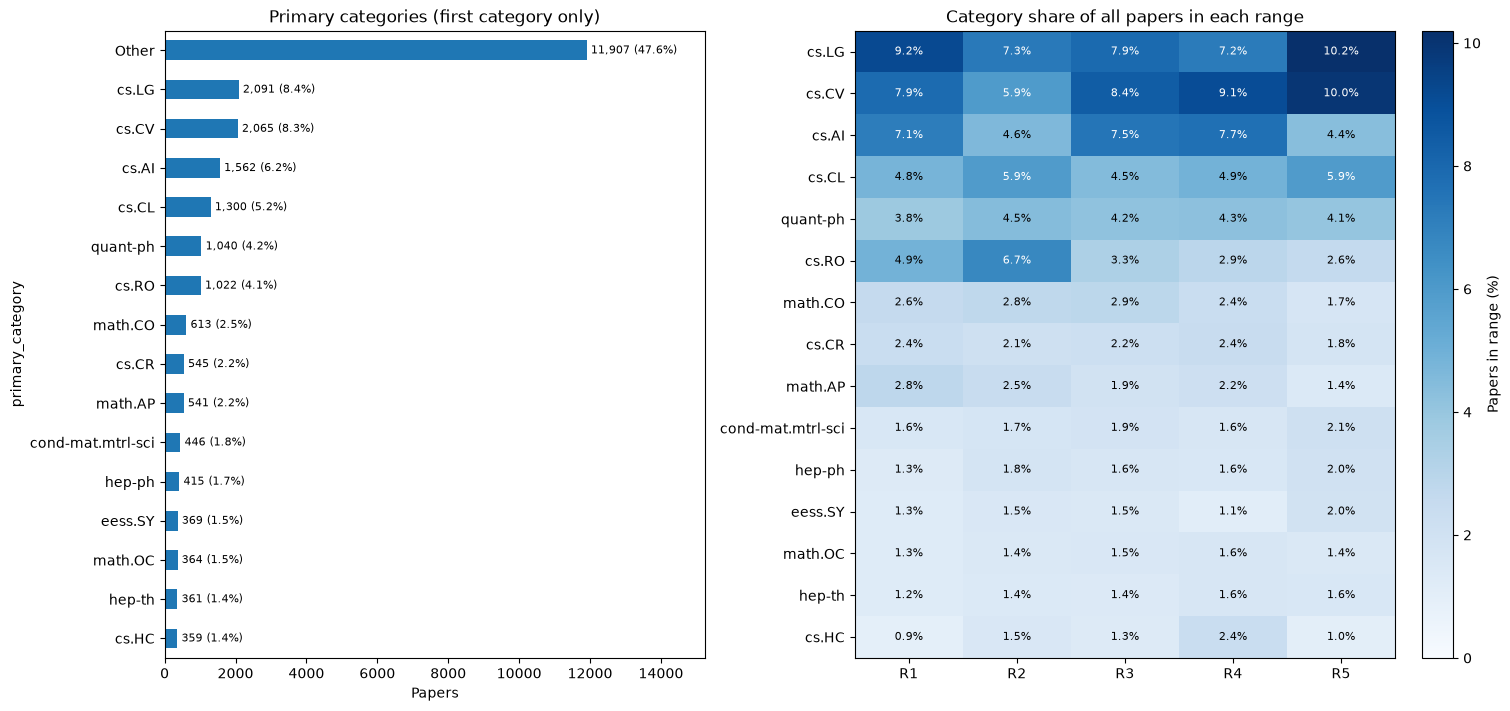

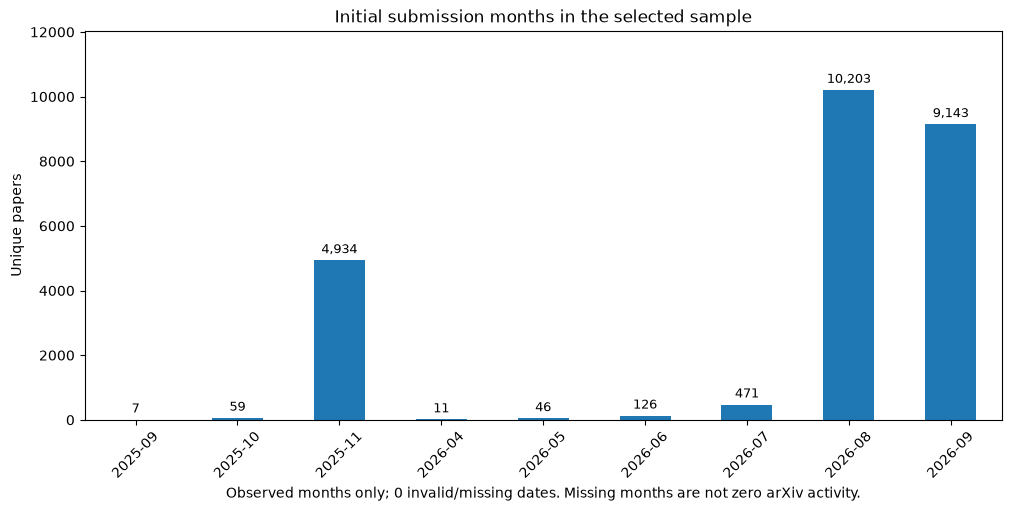

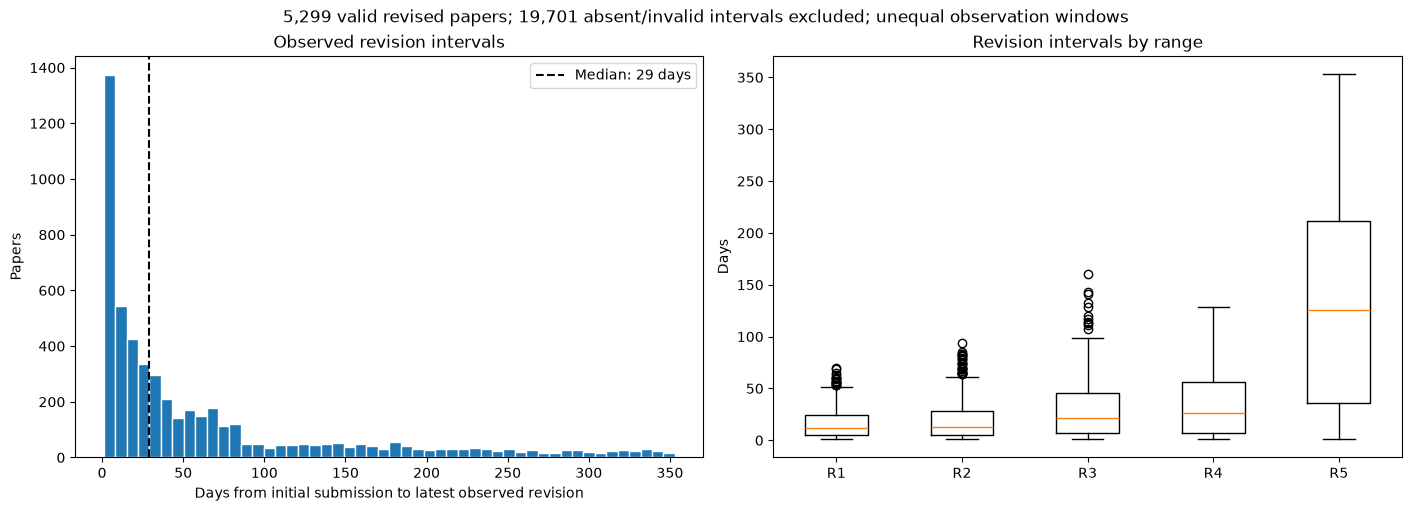

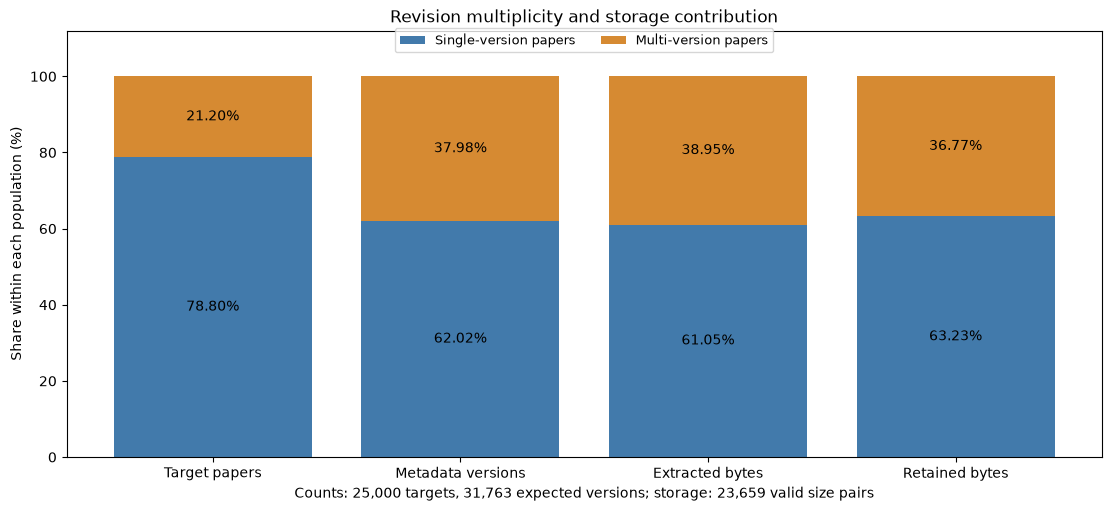

In [5]:
num_version = m1s3.num_version_34()
primary_category = m1s3.primary_category_34()
submission_timeline = m1s3.submission_timeline_34()
revision_history = m1s3.revision_history_34()
version_storage_profile = m1s3.version_storage_profile_34()

# 4. Performance Evaluation

This section evaluates the performance of the Milestone 1 pipeline in collecting 25,000 arXiv IDs, based on running time, memory footprint, storage, and the causes of the throughput limits. All results come from the actual collection, which ran over many Colab sessions instead of one complete session.

Five team members each ran one worker on one ID range (R1–R5) from October 31 to November 3, 2026. Sessions were interrupted and resumed, and different workers often ran at the same time. Therefore, execution time is reported in three ways:
 - **Calendar elapsed:** from the start of the first session to the end of the last session, including the time when nothing was running.
 - **Active collection elapsed:** the time during which at least one session was running.
 - **Worker time:** the sum of all session durations, in worker-hours.

We use these conventions in this section:
 - Stage times (Metadata, Source, References) are work times per paper. When one request covers a batch of IDs, its time is divided evenly among them. These times are not equal to elapsed wall time.
 - RAM (RSS) and directory sizes are sampled values. Missing samples are not counted as zero, and short peaks between samples can be missed.
 - Sizes use binary units: 1 MiB = 2²⁰ bytes, 1 GiB = 2³⁰ bytes.

Section 4.1 describes the testbed and instrumentation, Section 4.2 analyzes running time per stage, Section 4.3 examines memory and storage, Section 4.4 collects the results in one table, and Section 4.5 discusses the main bottlenecks.

## 4.1 Benchmarking Methodology & Testbed Environment
The measurements were taken during the actual collection of the 25,000 papers, which consists of 48 recorded sessions, including 2 short test sessions on R5 with `SAMPLE_N = 20`. The team ran all sessions on Google Colab in CPU-only mode. The runtime type itself is not written to the logs, but the hardware of each session is. Sessions ran on either an Intel Xeon (34 sessions) or an AMD EPYC 7B12 (14 sessions), in both cases with 2 logical CPUs and 12.67 GiB of RAM.

### Measurement Tools
- **Hardware:** Logged at the start of each session from `/proc/cpuinfo`, `os.cpu_count()`, `psutil.virtual_memory()`, and `shutil.disk_usage`.
- **RAM:** A background thread uses `psutil` to sample the RSS of the scraper process and its child processes every 1 s (median gap 1.00 s, maximum 1.59 s). Peak RAM is the largest sample, and average RAM is the time-weighted mean of the samples. The kernel's `ru_maxrss` is also written at the end of a session. It covers the whole lifetime of the kernel and excludes child processes, so it is kept as a reference value.
- **Disk:** `data/` is stored on Google Drive. Its size is the sum of the sizes of all files under it, including logs and state files, and is computed every 300 s (median gap about 310 s).
- **Stage time:** Three stages are timed: Metadata (entry discovery), Source, and References. The Source timer covers the download of all revisions of a paper, including pacing and retries. Extraction, file filtering, and writing run on a background thread, which has one combined timer per session (`writer_busy_sec`). CPU time is not measured.
- **Session time:** Start and end times come from the run logs. A session that stopped before writing its end record uses its latest log record as the end time, so its duration is a lower bound.

The tables below show the hardware profiles, the pipeline settings, which were the same in every session, and the number of sessions with each type of measurement. `Disk_GiB` is the local disk of the virtual machine, not Google Drive. Peak and average RAM describe the 45 sessions with RSS samples.

CPU,logical_CPUs,RAM_GiB,Disk_GiB,Python,Sessions,Workers
AMD EPYC 7B12,2,12.67,107.7,3.13.18,14,"R4, R5"
Intel(R) Xeon(R) CPU @ 2.20GHz,2,12.67,107.7,3.13.18,34,"R1, R2, R3, R4, R5"


Setting,Value,Unit
arXiv base delay between request starts,3.0,seconds
arXiv maximum delay after 429 / 5xx,6.0,seconds
Metadata batch size,100,IDs per request
Semantic Scholar batch size,100,IDs per request
Semantic Scholar delay with API key,1.0,seconds
arXiv and Semantic Scholar run in parallel,True,
Keep source archives on disk,False,
Time limit per session,11.5,hours


Measurement,Sessions with data (of 48)
Session duration,47
Stage timings,47
RSS samples,45
data/ size scans,41
Kernel peak RSS,29


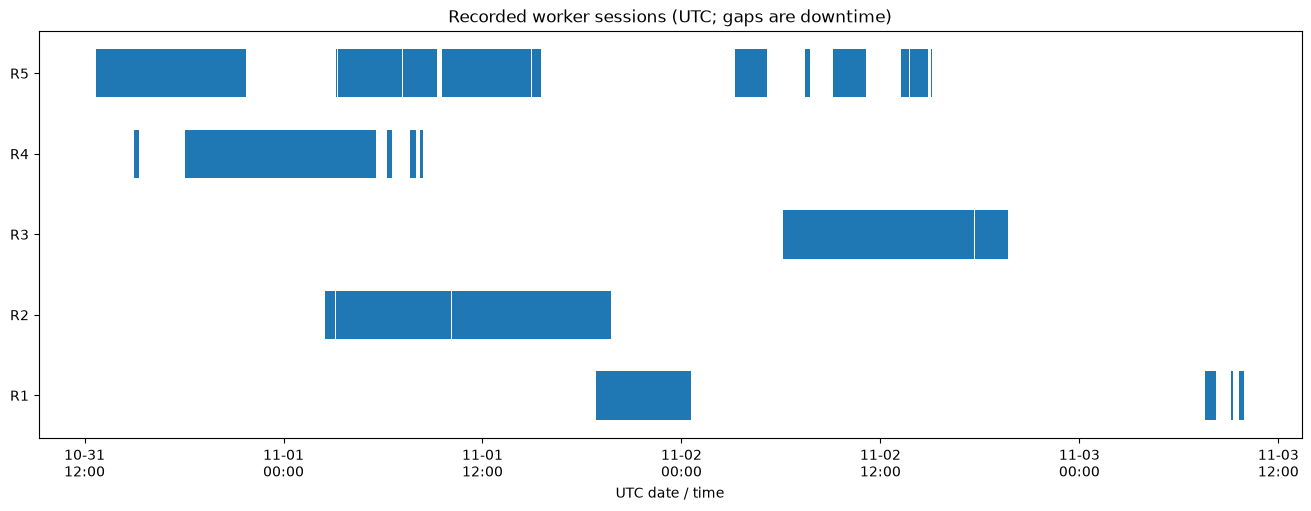

In [6]:
hardware = m1s4.hardware_41()
profile = (
    hardware.assign(RAM_GiB=hardware.RAM_GiB.round(2),
                    Disk_GiB=hardware.disk_capacity_GiB.round(1))
    .groupby(["CPU", "logical_CPUs", "RAM_GiB", "Disk_GiB", "Python"])
    .agg(Sessions=("run_id", "size"),
         Workers=("worker", lambda s: ", ".join(sorted(set(s)))))
    .reset_index()
)
display(profile.style.format({"RAM_GiB": "{:.2f}", "Disk_GiB": "{:.1f}"}).hide(axis="index").set_caption("Hardware profiles"))
display(m1s4.pipeline_config_41().style.hide(axis="index").set_caption("Pipeline settings"))
display(m1s4.measurement_coverage_41().style.hide(axis="index").set_caption("Sessions with data"))

session_timeline = m1s4.session_timeline_41()

From the chart, we can see that the sessions did not run continuously. The whole process took about 69 hours, but only about 52 hours had at least one session running. The longest break was about 11.9 hours, from when R3 finished on November 2 until R1 ran its last sessions on November 3.

Different workers also ran at the same time. For about 21.3 hours, two or more workers were running, and at most 3 workers ran together. This is the reason worker time is larger than active elapsed time. R3 needed 2 sessions, but R5 needed 29.

19 sessions (16 on R5 and 3 on R2) have no end record because they were cut off before they could write it. Their session times, kernel peaks, and end-of-session counters are incomplete. The collected data is not affected, because the next session continued from the saved state. The long R5 bar on October 31 is one of these sessions (`R5-20261031-130001`), and it also has no RSS samples. Three R2 sessions also overlap for about 0.97 hours, and their bars are drawn on top of each other. Their RSS and local disk values are different, so they probably did not all run in the same Colab runtime. In the end, 24,999 of the 25,000 papers were collected successfully.

## 4.2 Running Time Analysis
This section analyzes the time spent in the 3 timed stages: Metadata (entry discovery), Source, and References. Source covers the download of every revision. Extraction and file writing are discussed in Section 4.5.

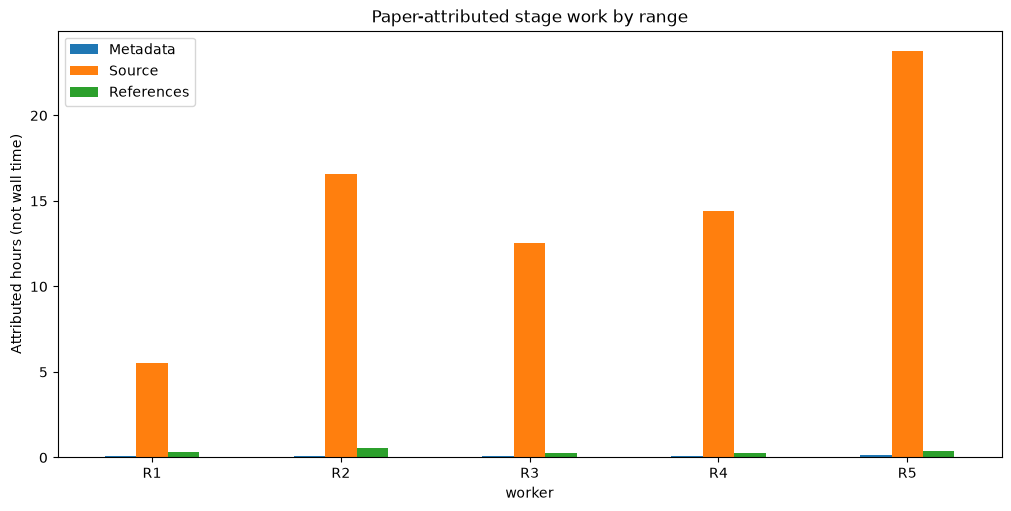

In [7]:
attribute_stage_time_by_range = m1s4.attribute_stage_time_by_range_42()

From the chart, we can see that Source takes most of the time in every range. It accounts for about 96.9% of the total, while References accounts for about 2.4% and Metadata for about 0.7%. Metadata and References are fast because one request can handle up to 100 IDs, and the request time is divided among them.

R5 has the highest total (about 24.3 hours) and R1 has the lowest (about 6 hours). One reason is the number of versions, because each version is downloaded separately. Papers in R5 have 1.56 versions on average, while the other ranges have about 1.15 to 1.23. The average Source time is about 8.1 seconds for papers with 1 version and about 16.6 seconds for papers with 2 versions. However, versions do not explain everything. R1 and R2 have a similar number of versions, but R2 took about 3 times longer in Source. Section 4.5 looks at the reason for this.

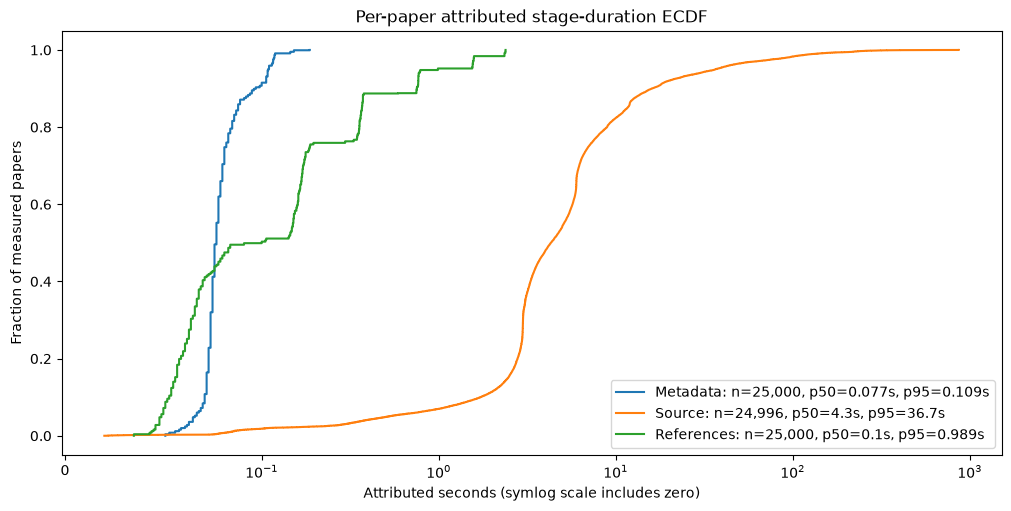

In [8]:
stage_duration_per_paper = m1s4.stage_duration_per_paper_42()

The second chart shows that Source time is very uneven between papers. Half of the papers finished downloading within 4.3 seconds and 95% within 36.7 seconds, but the slowest paper took about 868 seconds (14.5 minutes). These long downloads are why the mean (10.5 seconds) is more than twice the median. The jump near 3 seconds is likely caused by the 3-second delay between arXiv requests. Four papers have no Source time and are not included in the chart.

## 4.3 Memory Footprint & Storage Analysis
This section looks at RAM use during each session and at the size of `data/` over time.

The maximum RAM was about 952 MiB and the average was about 403 MiB. The maximum is only about 7% of the 12.67 GiB available on the Colab machine, so RAM was not a limit for the scraper.

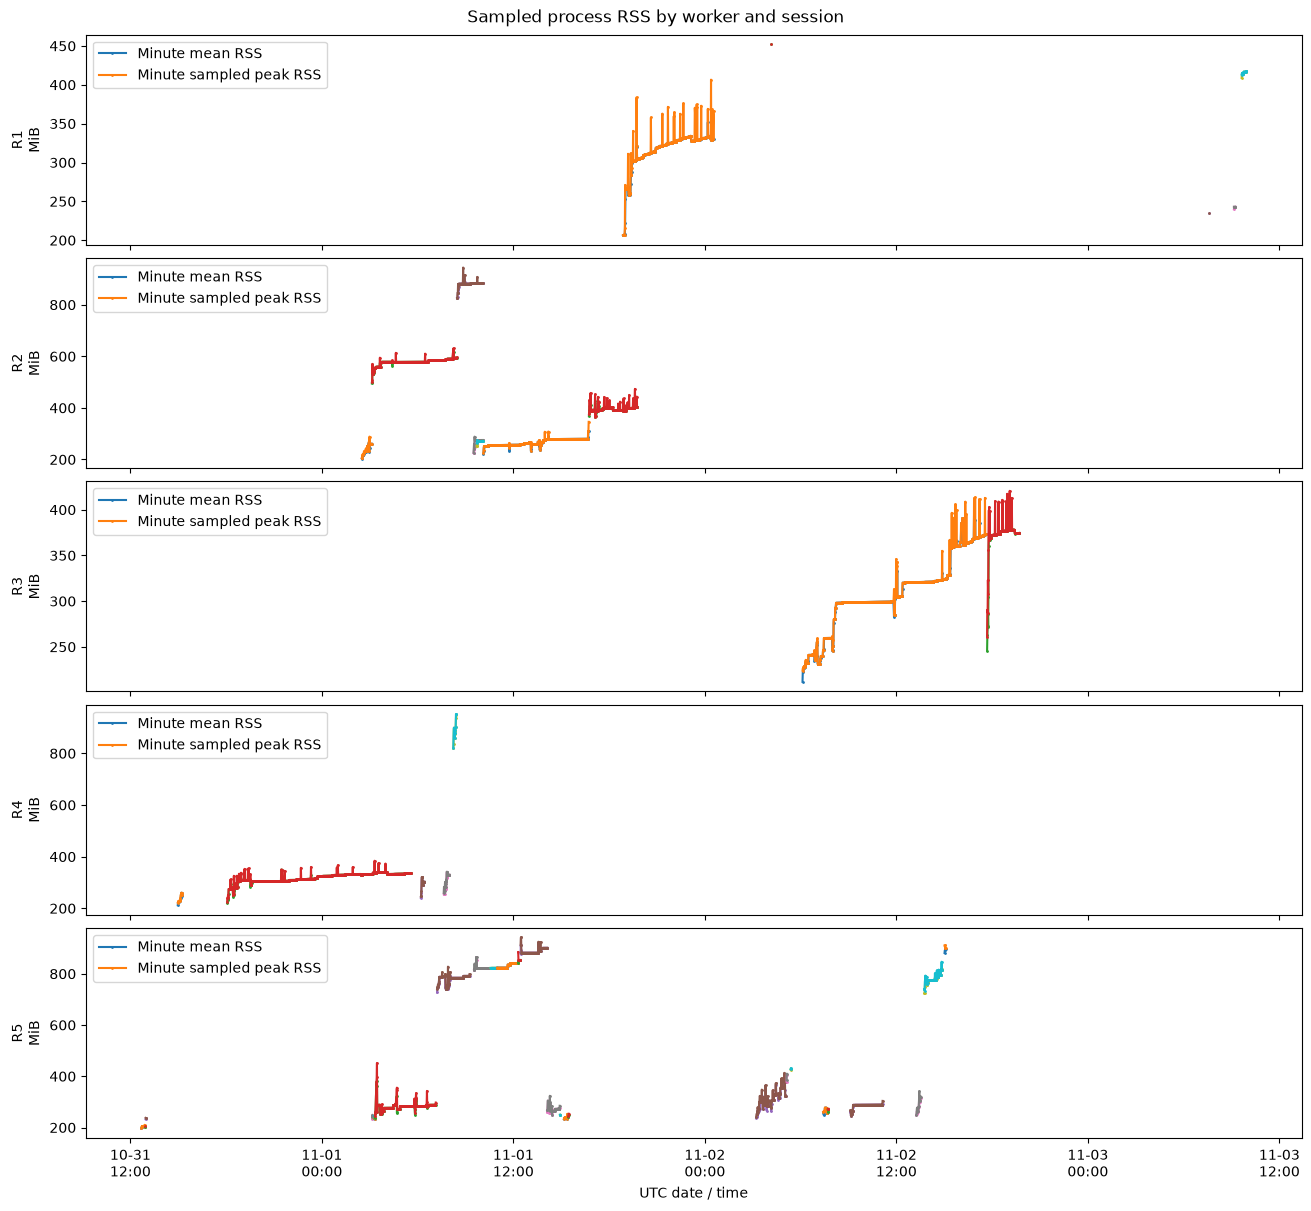

In [9]:
memory_over_execution  = m1s4.memory_over_execution_43()

From the chart, we can see that most sessions stayed between about 200 and 450 MiB. RAM goes up slowly during a session, with short spikes. Even the two 11.5-hour sessions on R3 and R4 stayed below about 420 MiB, so a long run does not use much more RAM.

The values above 700 MiB come from 10 sessions. These sessions did not climb to this level during the run. They already started at about 700 to 860 MiB, while most other sessions started at about 200 to 270 MiB. This likely means they ran in a kernel that still held memory from earlier work. So the 952 MiB maximum is a real measurement, but normal use of the scraper is closer to 450 MiB.

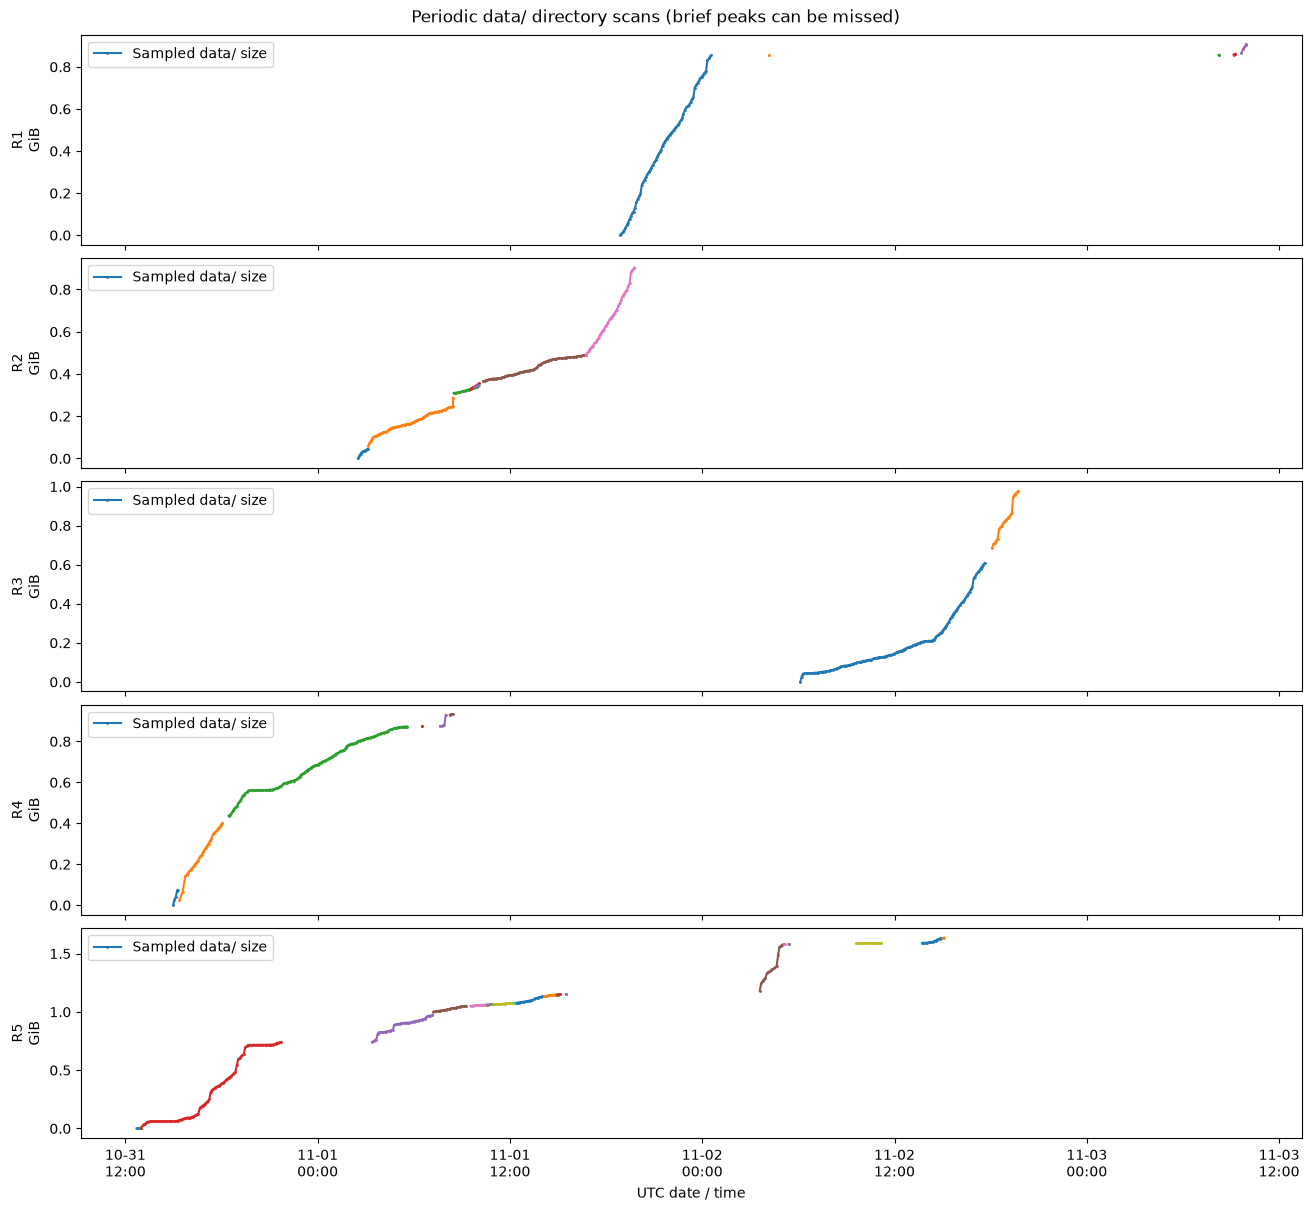

In [10]:
directory_size_over_time = m1s4.directory_size_over_time_43()

The size of `data/` grows steadily during the collection. R5 ends as the largest at about 1.64 GiB, while the other ranges reach about 0.90 to 0.98 GiB. The breaks in the lines are times with no running session or no scan. The few small decreases on R2 come from alternating scans of its overlapping sessions, and R4 shows one drop of about 52 MiB between two early sessions.

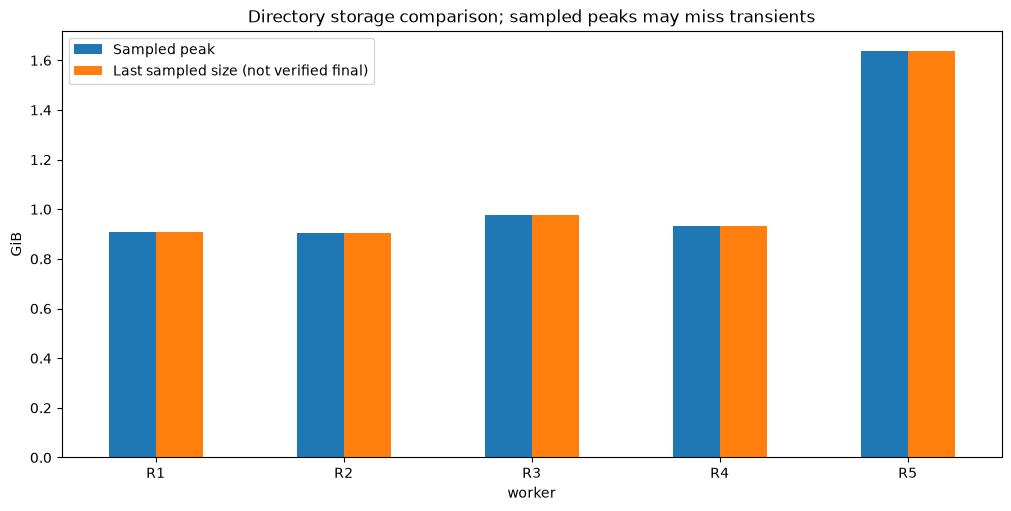

In [11]:
temporary_storage_overhead = m1s4.temporary_storage_overhead_43()

In all 5 ranges, the largest scan is also the last one, so the scanned size never rose above its final level. This fits how the scraper works, because archives are processed in RAM and are not saved to disk.

The scans cover everything under `data/`, while the final output counts only the paper folders, without logs, state files, and exported tables. The final output of the 5 ranges is about 5.15 GiB, and the exported Parquet tables add about 0.17 GiB. Keeping only `.tex` and `.bib` files reduced the extracted source from about 109.12 GiB to about 4.84 GiB, a reduction of 95.56%, measured on the 23,659 papers that have both sizes.

## 4.4 Performance Metrics Summary Table
The table below collects the main metrics of the collection. The `Population/scope` column states what each value covers, and the `Source` column names the file it comes from. The metrics required by the project are discussed after the table.

In [12]:
import warnings

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Missing raw memory samples")
    summary = m1s4.summary_table_44()

display(
    summary.style
    .format({"Value": "{:,.2f}"}, na_rep="N/A")
    .hide(axis="index")
)

Metric,Value,Unit,Population/scope,Source
Target IDs,"25,000.00",papers,All target IDs,per_paper.csv
Metadata found,"25,000.00",papers,All target IDs,per_paper.csv
Successful papers,"24,999.00",papers,All target IDs,per_paper.csv
Overall paper success,100.00,%,Successful / target IDs,per_paper.csv
Reference outcome: ok,"21,835.00",papers,All requested papers,per_paper.csv
Reference outcome: no_refs,"3,155.00",papers,All requested papers,per_paper.csv
Reference outcome: not_found,10.00,papers,All requested papers,per_paper.csv
Reference retrieval success,87.34,%,ok / all requested papers,per_paper.csv
Workers,5.00,workers,Recorded sessions,runs.csv
Sessions,48.00,sessions,"Unique (worker, run_id)",runs.csv


The names in brackets are the matching rows in the table.

**Running time**
- Time to process one paper: 4.77 s at the median and 37.06 s at the 95th percentile (`Median attributed paper time`, `p95 attributed paper time`).
- Average time per paper: 10.83 s (`Mean attributed paper time`).
- Total time for entry discovery: 2,005.90 s, or about 33 minutes (`Entry discovery total`).

**Memory footprint**
- Maximum RAM: 951.76 MiB (`Raw sampled peak RSS`).
- Average RAM: 403.07 MiB (`Time-weighted sampled RSS`).
- Maximum disk storage: 1.64 GiB on one worker (R5), and 0.90 to 0.98 GiB on the other workers (`Sampled peak directory size`). The five `data/` folders reach 5.36 GiB in total.
- Final output size: 5.15 GiB of paper folders across the 5 ranges (`Final output size (all ranges)`), or 5.32 GiB with the exported tables.

For the whole collection, the active elapsed time was 52.31 hours, the calendar elapsed time was 69.25 hours, and the worker time was 77.75 worker-hours. With 24,999 successful papers, this gives 477.88 papers per active hour and 321.54 papers per worker-hour.

Paper times are attributed work times. They cover metadata, downloads, and reference lookups, but most extraction and file writing happen in the background (Section 4.5). 19 sessions have no end time and one of them has no logs at all, which leaves 47 of the 48 sessions with a measured duration. This makes active elapsed time a lower bound and the collection throughput an upper bound. Worker time has the same problem, and it also includes the 0.97 hours in which three R2 sessions overlap.

The RAM figures describe the 45 sessions with RSS samples. We do not know the memory use of the other 3 sessions, and one of them is an R5 session of at least 8.7 hours. The kernel-labelled peak of 951.59 MiB exists in 29 sessions and covers the whole kernel lifetime, so we keep it as a reference value.

On each virtual machine, the scraper is a single multi-threaded process. RSS is measured for the whole process and its children, which means all threads are included. The requirements say that the memory footprint of a system with several programs is the total memory of the full system. The 5 workers are the same program running on separate virtual machines, so we report the highest RAM of one worker and do not add the peaks together. For disk, we give both the highest value of one worker and the total of all workers, because files stay in storage after they are written.

## 4.5 Bottleneck Discussion: Rate Limiting vs. Compute & IO
Source takes about 96.9% of the attributed stage time, so this section focuses on the Source stage.

Each session sends its arXiv requests through one connection, and two request starts are at least 3.0 s apart. This 3.0 s is the base interval, and the time spent on a download counts toward it. After HTTP 429 or a server error, the interval grows by 1 s each time, up to 6.0 s. After every 100 successful requests in a row, it goes back down by 0.5 s until it reaches 3.0 s.

The Source timers record the time needed to download the revisions of each paper and the part of that time spent sleeping. Sleeping includes both pacing and waits after errors.

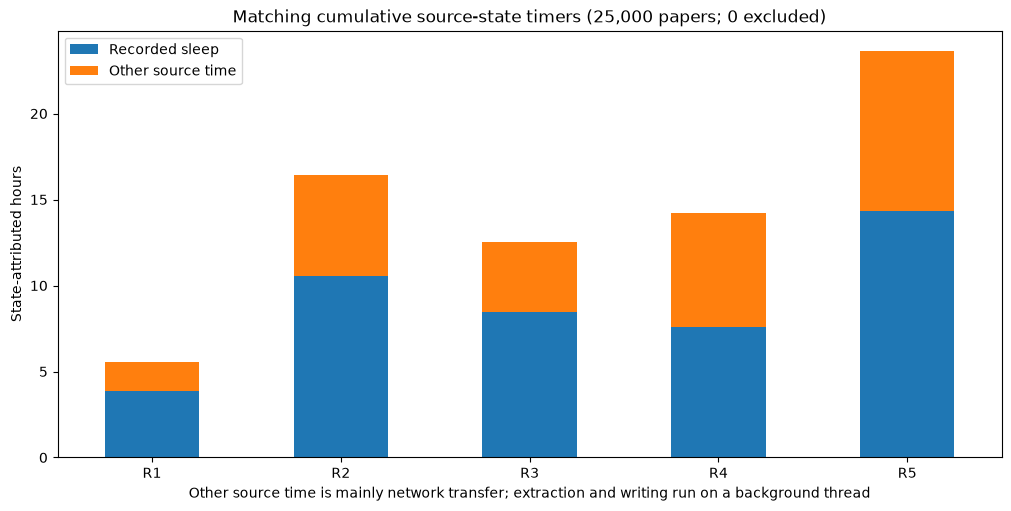

In [13]:
source_waiting = m1s4.source_waiting_45()

From the chart, we can see that sleeping is the largest part of the Source time in every range. The timers stored in the source state give a total of 72.36 hours across the 25,000 papers, close to the 72.84 hours logged per attempt in Section 4.4. Of this, 44.80 hours (61.9%) were sleep and 27.57 hours (38.1%) were other time. The share of sleep ranges from 53.2% on R4 to 69.7% on R1. The median paper spent 2.90 s sleeping and 0.54 s on other time.

The 3.0 s base interval alone does not explain all of this time. The 31,763 revisions need at least 26.47 worker-hours at one request every 3.0 s, which is about 37% of the Source time. The rest comes from the slower interval after errors, waits before retries, and downloads that take longer than the interval. Pacing and waits after errors share one timer, so we do not know the share of each.

Extraction and file writing run on a background thread and are mostly outside these timers. The other 38.1% is therefore mainly network transfer. The background thread has its own timer (`writer_busy_sec` in `runs.jsonl`). It was busy for 0.75 hours in the 29 sessions with an end record, about 1.3% of their 59.47 hours.

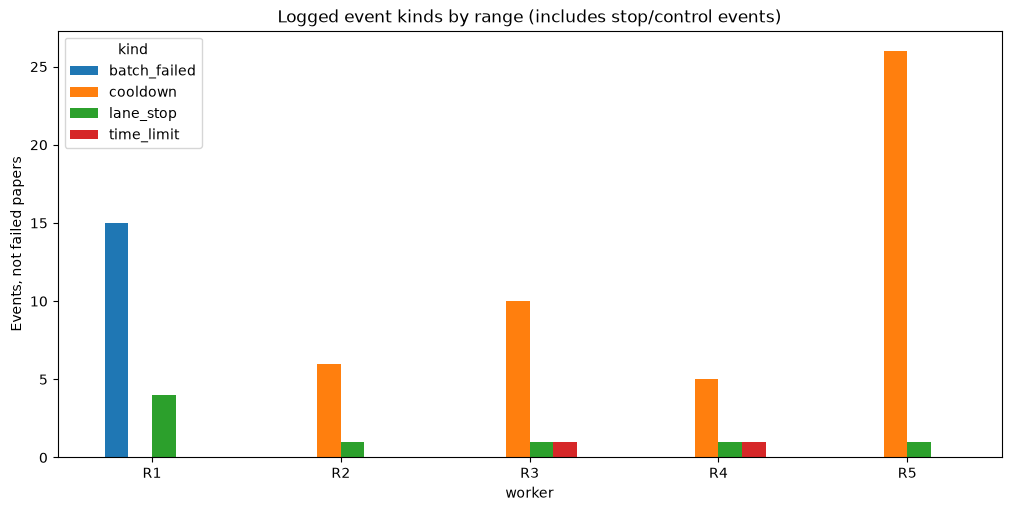

In [14]:
retry_errors_count = m1s4.retry_errors_count_45()

This chart counts logged events, not failed papers. On the arXiv side, there were 47 cooldowns, none of them on R1, and the arXiv lane stopped twice (R4 and R5) after 5 errors in a row. On the Semantic Scholar side, the lane stopped 6 times. Three of these were on R1 after 5 failed batches in a row, and the other 3 (R1, R2, and R3) happened because the quota was exhausted. All 15 failed batches are on R1. The 2 `time_limit` events are the R3 and R4 sessions that reached the 11.5-hour limit. Later sessions continued the remaining work from the saved state.

The retry counters in Section 4.4 show 1,977 interrupted downloads, 920 rate-limited responses, and 6 network errors. These counters are written in the end record of a session. The 19 sessions without one are not counted, so the real numbers are likely higher. R1 had 1 retry while R2 had 859, which is likely part of the reason why R2 took about 3 times longer in Source.

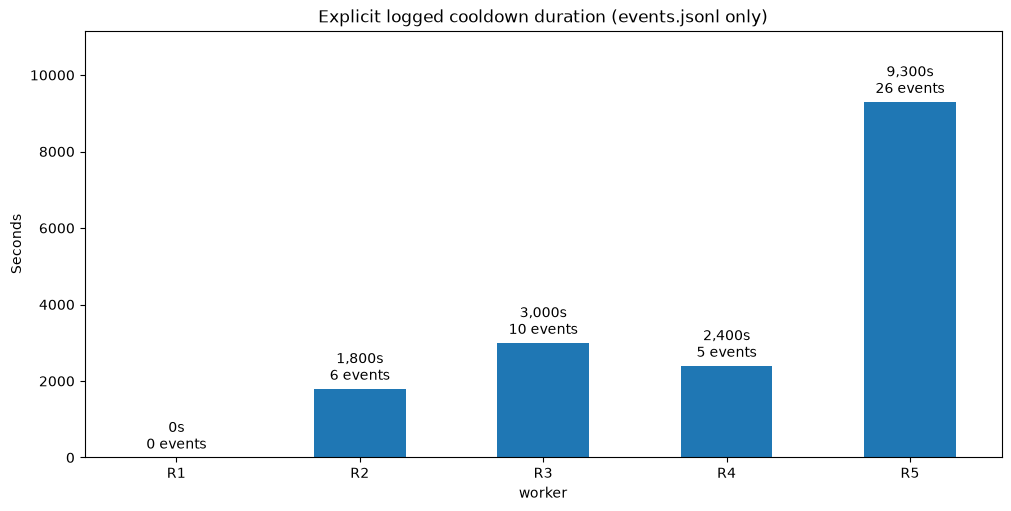

In [15]:
cooldown_duration = m1s4.cooldown_duration_45()

Cooldowns add another 16,500 s (about 4.58 hours), which is about 6% of the worker time. They run outside the stage timers, so they are not included in the Source time above. R5 has the most at 9,300 s from 26 cooldowns, followed by R3 (3,000 s), R4 (2,400 s), and R2 (1,800 s). 41 of the 47 cooldowns lasted 300 s, which is the first step of the 300, 600, and 900 s schedule.

RAM and storage did not limit the collection in our measurements. The highest sampled RAM is 951.76 MiB, about 7% of the 12.67 GiB on the Colab machine. Source archives, about 89.92 GiB in total, were processed in memory and not written to disk, because `KEEP_ARCHIVE` is `False` on all 5 workers. The largest `data/` scan on one worker was 1.64 GiB.

Each session already runs the arXiv and Semantic Scholar lanes at the same time, and a background thread does extraction and file writing while the next download runs. A session uses one arXiv connection because the project asks for at least 3 s between calls and one connection at a time. To collect faster, we split the IDs into 5 ranges on separate machines. Making reference scraping faster would not save much, because References is about 2.4% of the stage time.

Overall, the scraper spent most of its time waiting for arXiv because of pacing, waits after errors, and cooldowns. Extraction and file writing took about 1.3% of the measured session time, and RAM and storage were not a problem. CPU time was not measured, so we do not know how much time was spent on computation.

# 5. Conclusion

## 5.1 Key Results & Findings

Milestone 1 retrieved metadata for all **25,000 target arXiv IDs** and completed source processing for **24,999 papers (99.996%)**. Of the 31,763 metadata-reported versions, **30,050** retained TeX/Bib content, 1,598 had no retained TeX/Bib content, 114 were not found, and one remained incomplete. The high paper-level completion rate therefore describes completion of the workflow, including terminal outcomes without source files. Saved progress allowed collection to continue across interrupted sessions, although repeated interrupted downloads left the third version of `2608.08374` incomplete (Section 3.1).

Source filtering substantially reduced storage requirements. For the **23,659 valid size pairs**, extracted content decreased from **109.12 GiB to 4.84 GiB**, an **aggregate reduction of 95.56%**. The median per-paper reduction was 90.01%, while the mean was 69.80%, showing that savings varied considerably between papers. These measurements cover all removed file types, rather than figures alone. Final paper folders occupied about **5.15 GiB**, or **5.32 GiB** including exported Parquet tables (Sections 3.2 and 4.3–4.4).

Reference retrieval returned nonempty results for **21,835 papers (87.34%)**, producing **697,512 reference rows**. Among these rows, 55.73% contained an arXiv ID, while titles and Semantic Scholar IDs were present in every row. Coverage varied by range: R5 had a nonempty lookup rate of **73.44%**, compared with **90.82%** across R1–R4. Although R5 had the highest reference count among nonempty lookups, it had the lowest returned-reference yield per target. Downstream citation analysis must therefore account for both lookup coverage and identifier availability (Section 3.3).

The performance results identify source downloading and waiting as the main throughput constraints. Source accounted for **96.9% of attributed stage time**, and **61.9% of source-state time** was spent sleeping for pacing or retries. Cooldowns added another **4.58 worker-hours** outside the stage timers. Recorded collection time was **52.31 active hours**, **69.25 calendar hours**, and **77.75 worker-hours**; these measures describe different scopes. Sampled peak and time-weighted average RAM were **951.76 MiB** and **403.07 MiB**, respectively. The measurements indicate that request pacing, retry waits, and network transfer constrained collection more than memory or storage (Section 4).

---

## 5.2 Limitations & Challenges

- **Incomplete source and reference coverage:** Workflow completion does not guarantee usable LaTeX for every version. Likewise, the 3,155 empty reference results and ten unresolved lookups do not establish that those papers have no bibliography. The exports do not establish the cause of R5's lower reference coverage, and field presence alone does not verify metadata accuracy.
- **Restricted sampling and observation windows:** The five fixed ID ranges are not a random sample of arXiv. Category shares, submission timelines, and revision intervals describe this corpus. R5's earlier ID window gives more opportunity to observe revisions, so its higher multi-version share and longer revision intervals cannot establish intrinsic differences in revision behavior (Section 3.4).
- **Incomplete performance measurements:** Nineteen sessions lack end records, and only 45 of 48 sessions have RSS samples. Reported elapsed and worker times are lower bounds, making the corresponding throughput estimates upper bounds. Periodic storage scans can miss brief peaks, pacing and retry sleeps share one timer, and CPU time was not measured. These limits prevent a complete separation of network, compute, and I/O costs (Section 4).

The collected corpus provides input for the parsing and citation-analysis tasks in subsequent milestones. Those tasks should preserve paper- and version-level availability indicators, distinguish empty reference results from unresolved lookups, and report the population used in each analysis. More complete session-end logging and separate pacing, retry, transfer, and processing measurements would make future performance comparisons more reliable.
